# Enveda CASMI26 Baseline

### Install Libraries

### Dependencies

**Goal:** Record the packages the notebook needs (all commented out; Kaggle supplies them).

**Found**
- No output.
- `rdkit==2026.3.3` is the one that matters: the metric's InChIKey14 comes from RDKit's tautomer canonicaliser, so another version could change the keys.
- `lightning` and `tokenizers` are unused here, probably left over for later neural models.

> **Decision:** Keep RDKit pinned to the metric's version everywhere, including locally.

In [1]:
# Use the Dependency Manager
# !pip install lightning
# !pip install tokenizers
# !pip install rdkit==2026.3.3

### Imports

**Goal:** Load the stack for the three jobs ahead: data (pandas/numpy), chemistry (RDKit) and modelling (sklearn).

**Found**
- RDKit does SMILES parsing, tautomer canonicalisation, Murcko scaffolds, Morgan fingerprints and exact masses.
- `RDLogger.DisableLog` silences per-molecule warnings that would flood the output over ~30k molecules.

> **Decision:** Model family (Ridge) and splitter (grouped, not random) are fixed here.

In [23]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import os
from tqdm import tqdm
from rdkit import Chem, RDLogger
from rdkit.Chem import Descriptors, rdFingerprintGenerator
from rdkit.Chem.Scaffolds import MurckoScaffold
from rdkit.Chem.MolStandardize import rdMolStandardize
from sklearn.linear_model import Ridge
from sklearn.model_selection import GroupShuffleSplit
RDLogger.DisableLog("rdApp.*")

### Data Loading & Exploration

### Paths and column names

**Goal:** Point at the competition files and name the key columns (`normalized_smiles`, `inchikey14`; the file's key is called `PROV_KEY` to separate it from the canonical key computed later).

**Found**
- `./data` contains `train.parquet`, `test.parquet` and `sample_submission.csv`.
- `test.parquet` is present but **never opened** in this notebook.
- `WORKING_DIR` / `SUBMISSION_PATH` still point to `/kaggle/working`, which doesn't exist locally.

> **Decision:** The P1 unknowns (formula vs precursor m/z only, spectra per molecule, adducts, instruments) can be answered by inspecting `test.parquet` directly.

In [3]:
# Competition paths. The input directory is mounted read-only; everything we write goes to
# /kaggle/working, which is what Kaggle collects as the notebook's output.
# COMP_DIR = '/kaggle/input/competitions/enveda-CASMI26-molecule-id-mass-spectra'
COMP_DIR = './data'

TRAIN_PATH = os.path.join(COMP_DIR, 'train.parquet')
SMILES_COL, KEY_COL = "normalized_smiles", "inchikey14"
PROV_KEY   = "inchikey14"           # the key supplied in the file

TEST_PATH = os.path.join(COMP_DIR, 'test.parquet')

WORKING_DIR = '/kaggle/working'
SAMPLE_SUB_PATH = os.path.join(COMP_DIR, 'sample_submission.csv')
SUBMISSION_PATH = os.path.join(WORKING_DIR, 'submission.csv')

print(os.listdir(COMP_DIR))

['train.parquet', '.DS_Store', 'test.parquet', '.gitkeep', 'sample_submission.csv']


### Load the training table

**Goal:** Read the full file and keep an untouched copy (`df_raw`) so later cells can measure what cleaning removed.

**Found**
- **2,539,608 spectra x 18 columns**, matching CONTEXT.md.

> **Decision:** Memory-heavy. Later `src/` modules should cache derived tables in `artifacts/` rather than refilter 2.5M rows each session.

In [4]:
df = pd.read_parquet(TRAIN_PATH)    # or read_csv, as before
print(df.shape)

df_raw = df.copy()

(2539608, 18)


### Cleaning filters and neutral mass

**Goal:** Keep only usable spectra and convert each precursor m/z into the molecule's **neutral mass**, the number later compared with candidate masses.

**Found**
- Adduct (the extra ion the molecule picked up, e.g. +H, +Na) must be in the table; dimers are off (`KEEP_DIMERS=False`).
- Also required: precursor m/z 50-1500, |error| <= 20 ppm, 3-500 peaks.
- Neutral mass = `(mz - shift) / n_mol`. Array-valued collision energy becomes its mean plus a `ce_multi` flag (bug #1 fix).
- **1,734,548 of 2,539,608 spectra kept (68.3%)**, covering 253,832 molecules; 14.6% have no collision energy.
- `enveda-180` dominates (167,526 molecules); `enveda-np-examples` has only 238.

> **Decisions**
> - Every threshold is a hypothesis; the next three cells test them.
> - The neutral-mass formula enables the mass-window filter, which turns out to be the biggest lever.

In [34]:
# Each adduct: (number of molecules in the ion, mass the ion gained/lost in Da)
ADDUCT = {
    "[M+H]+":       (1,  1.007276), "[M-H]-":      (1, -1.007276),
    "[M+Na]+":      (1, 22.989218), "[M+NH4]+":    (1, 18.033823),
    "[M+CH2O2-H]-": (1, 44.997655),
    "[2M+H]+":      (2,  1.007276), "[2M-H]-":     (2, -1.007276),
    "[2M+Na]+":     (2, 22.989218),
}
KEEP_DIMERS = False
if not KEEP_DIMERS:
    ADDUCT = {k: v for k, v in ADDUCT.items() if not k.startswith("[2M")}

n0 = len(df)
df = df[
    df.adduct.isin(ADDUCT)
    & df.precursor_mz.between(50, 1500)
    & df.precursor_error_ppm.abs().le(20)
    & df.num_peaks.between(3, 500)
].copy()
print(f"kept {len(df):,} / {n0:,} ({len(df)/n0:.1%})")

# neutral mass of the original molecule, undoing the adduct
n_mol = df.adduct.map(lambda a: ADDUCT[a][0])
shift = df.adduct.map(lambda a: ADDUCT[a][1])
df["neutral_mass"] = (df.precursor_mz - shift) / n_mol

# collision energy: some rows hold arrays (stepped energies). Collapse to one number + a flag.
def ce_scalar(x):
    if isinstance(x, (list, tuple, np.ndarray)):
        a = np.asarray(x, float)
        return np.nan if a.size == 0 else float(np.nanmean(a))
    try: return float(x)
    except (TypeError, ValueError): return np.nan

df["ce_multi"] = df.collision_energy_ev.apply(
    lambda x: isinstance(x, (list, tuple, np.ndarray))).astype(np.float32)
df["collision_energy_ev"] = df.collision_energy_ev.apply(ce_scalar)

print("NaN collision energy:", df.collision_energy_ev.isna().mean().round(3))
print(df.groupby("ingest_lib")[PROV_KEY].nunique().sort_values(ascending=False))
print("unique molecules:", df[PROV_KEY].nunique())

kept 1,734,548 / 1,734,548 (100.0%)
NaN collision energy: 0.146
ingest_lib
enveda-180            167526
pluskal_ms2            45763
gnps                   41088
riken                  13503
mona                    9732
spectraverse            8182
massbank                7768
msdial                  7764
drug_plus               2230
masaryk                  409
enveda-np-examples       238
Name: inchikey14, dtype: int64
unique molecules: 253832


### Attrition per source

**Goal:** Measure how many spectra and molecules each filter removes, per source, instead of trusting the thresholds.

**Found**
- `enveda-180` loses 29% to the adduct filter and another 13% to the peak filter, ending at 58%.
- Other sources lose mostly 5-15% to the ppm filter; missing ppm values are rare (max 3.1%, `massbank`).
- Molecules lost: 2-17% per source; highest for `mona` (16.7%), `massbank` (15.4%), `riken` and `spectraverse` (15%).

> **Decisions**
> - A spectrum filter is also a molecule filter: a molecule vanishes only when *all* its spectra fail.
> - Cell 12 repeats this one exactly and can be deleted.

In [7]:
SRC = "ingest_lib"
conds = {
    "adduct in table":  df_raw.adduct.isin(ADDUCT),
    "mz 50-1500":       df_raw.precursor_mz.between(50, 1500),
    "ppm known & <=20": df_raw.precursor_error_ppm.abs().le(20),
    "peaks 3-500":      df_raw.num_peaks.between(3, 500),
}
alive = pd.Series(True, index=df_raw.index)
surv = pd.DataFrame({"raw": df_raw.groupby(SRC).size()})
for name, c in conds.items():
    alive &= c
    surv[name] = df_raw[alive].groupby(SRC).size()
surv = surv.fillna(0).astype(int)
print("% of raw spectra surviving cumulatively:")
display((surv.div(surv.raw, axis=0) * 100).round(1))

print("\nfraction of rows with MISSING ppm error, per source:")
print(df_raw.groupby(SRC).precursor_error_ppm.apply(lambda s: s.isna().mean()).round(3))

mol_raw = df_raw.groupby(SRC).inchikey14.nunique()
mol_cln = df.groupby(SRC).inchikey14.nunique()
display(pd.DataFrame({"mols_raw": mol_raw, "mols_clean": mol_cln,
                      "mols_lost_%": (1 - mol_cln / mol_raw) * 100}).round(1))

% of raw spectra surviving cumulatively:


,raw,adduct in table,mz 50-1500,ppm known & <=20,peaks 3-500
ingest_lib,,,,,
drug_plus,100.0,90.7,90.6,87.7,87.7
enveda-180,100.0,70.9,70.9,70.9,58.1
enveda-np-examples,100.0,95.3,95.3,95.2,79.5
gnps,100.0,89.4,89.3,83.3,76.9
masaryk,100.0,100.0,100.0,100.0,97.1
massbank,100.0,95.2,95.1,86.0,77.5
mona,100.0,91.6,91.4,85.5,73.9
msdial,100.0,87.2,86.9,86.7,76.4
pluskal_ms2,100.0,92.4,92.4,82.7,81.5



fraction of rows with MISSING ppm error, per source:
ingest_lib
drug_plus             0.000
enveda-180            0.000
enveda-np-examples    0.000
gnps                  0.000
masaryk               0.000
massbank              0.031
mona                  0.008
msdial                0.000
pluskal_ms2           0.000
riken                 0.000
spectraverse          0.000
Name: precursor_error_ppm, dtype: float64


,mols_raw,mols_clean,mols_lost_%
ingest_lib,,,
drug_plus,2539,2230,12.2
enveda-180,182941,167526,8.4
enveda-np-examples,250,238,4.8
gnps,45750,41088,10.2
masaryk,416,409,1.7
massbank,9180,7768,15.4
mona,11681,9732,16.7
msdial,9127,7764,14.9
pluskal_ms2,46821,45763,2.3


### Why were spectra dropped?

**Goal:** Break down the three biggest losses: dropped adducts, peak-count failures, and rejected ppm errors.

**Found**
- **Adducts:** mostly dimers in `enveda-180` ([2M+Na]+ 188k, [2M+H]+ 89k, [2M-H]- 53k). `pluskal_ms2` also loses 23k [M+Cl]- and 11k [M-H2O+H]+.
- **Peaks:** `enveda-180` fails on *too many* (18.2% over 500); `riken` (19%), `msdial` (11%) and `massbank` (10%) fail on *too few* (under 3).
- **ppm:** medians are 1-4 ppm, but the 99th percentile reaches tens of thousands in `drug_plus`, `gnps`, `mona`, `riken`, so the cutoff removes garbage, not real measurements.
- **Lost molecules:** 21,978 of 275,810 (8%), split between adduct (10,346) and peaks (10,197). `enveda-180` alone loses 8,438 to peaks and 6,813 to adducts.

> **Decisions**
> - No threshold changed. Two ideas for the parking lot: truncate dense spectra to the top-K peaks instead of dropping them (recovers ~8.4k `enveda-180` molecules), and add [M-H2O+H]+, [M+K]+, [M+Cl]-.
> - The second matters because `enveda-np-examples` (the likely test domain) contains all three.

In [8]:
# 1) which adducts the adduct filter drops, by source
d = df_raw[~df_raw.adduct.isin(ADDUCT)]
ct = pd.crosstab(d[SRC], d.adduct.fillna("NaN"))
print("dropped adducts (top 8 by count):")
display(ct[ct.sum().sort_values(ascending=False).index[:8]])

# 2) peak filter: too few or too many? (rows that passed the other three filters)
pre = df_raw[conds["adduct in table"] & conds["mz 50-1500"] & conds["ppm known & <=20"]]
pk = pre.assign(lt3=pre.num_peaks < 3, gt500=pre.num_peaks > 500).groupby(SRC)[["lt3", "gt500"]].mean() * 100
print("\n% of otherwise-valid spectra failing the peak filter:")
display(pk.round(1))
print("\nnum_peaks percentiles (5/25/50/75/95) per source:")
display(pre.groupby(SRC).num_peaks.quantile([.05, .25, .5, .75, .95]).unstack().round(0))

# 3) ppm: how bad are the rejected rows? (abs error percentiles per source)
pa = df_raw[conds["adduct in table"] & conds["mz 50-1500"]].assign(a=lambda x: x.precursor_error_ppm.abs())
display(pa.groupby(SRC).a.quantile([.5, .9, .99]).unstack().round(1))

# 4) molecules lost entirely, and the first filter that killed each of their rows
reason = np.select([~c for c in conds.values()], list(conds), default="kept")
lost = set(df_raw.inchikey14) - set(df.inchikey14)
print(f"\nmolecules lost dataset-wide: {len(lost):,} of {df_raw.inchikey14.nunique():,}")
lr = df_raw[df_raw.inchikey14.isin(lost)].assign(reason=reason[df_raw.inchikey14.isin(lost).values])
display(pd.crosstab(lr[SRC], lr.reason))

dropped adducts (top 8 by count):


adduct,[2M+Na]+,[2M+H]+,[2M-H]-,[M+Cl]-,[M-H2O+H]+,[M+K]+,[M]+,[M+C2H4O2-H]-
ingest_lib,,,,,,,,
drug_plus,0,0,0,0,0,164,65,0
enveda-180,188158,89487,52933,2407,0,1084,0,376
enveda-np-examples,0,0,0,7,24,16,0,0
gnps,866,1664,2339,1416,6105,6334,1025,232
massbank,20,49,51,42,332,19,2378,992
mona,158,128,91,102,1007,4976,185,367
msdial,240,230,620,169,1115,194,135,861
pluskal_ms2,0,0,0,23021,11406,0,3598,0
riken,591,483,138,221,1693,5439,1134,830



% of otherwise-valid spectra failing the peak filter:


,lt3,gt500
ingest_lib,,
drug_plus,0.0,0.0
enveda-180,0.0,18.2
enveda-np-examples,0.0,16.5
gnps,1.1,6.5
masaryk,2.9,0.0
massbank,9.8,0.1
mona,1.1,12.5
msdial,11.2,0.6
pluskal_ms2,1.4,0.0



num_peaks percentiles (5/25/50/75/95) per source:


,0.05,0.25,0.50,0.75,0.95
ingest_lib,,,,,
drug_plus,10.0,40.0,121.0,200.0,200.0
enveda-180,16.0,88.0,211.0,408.0,938.0
enveda-np-examples,12.0,51.0,143.0,354.0,848.0
gnps,6.0,20.0,45.0,115.0,609.0
masaryk,3.0,6.0,9.0,14.0,28.0
massbank,2.0,5.0,12.0,29.0,93.0
mona,5.0,15.0,51.0,289.0,827.0
msdial,2.0,4.0,10.0,28.0,132.0
pluskal_ms2,4.0,12.0,23.0,48.0,126.0


,0.50,0.90,0.99
ingest_lib,,,
drug_plus,1.8,3.9,70165.8
enveda-180,1.0,2.7,4.1
enveda-np-examples,1.6,3.1,6.3
gnps,1.7,6.2,79909.0
masaryk,1.5,2.8,4.0
massbank,2.0,4.8,6735.9
mona,1.8,4.7,41443.8
msdial,1.5,3.6,6.1
pluskal_ms2,1.7,1305.9,2877.4



molecules lost dataset-wide: 21,978 of 275,810


reason,adduct in table,mz 50-1500,peaks 3-500,ppm known & <=20
ingest_lib,,,,
drug_plus,65,2,0,2
enveda-180,29815,0,38872,0
gnps,1907,269,1495,1758
massbank,2930,115,181,267
mona,504,187,56,365
msdial,1223,114,111,26
pluskal_ms2,2208,62,57,1234
riken,1930,452,305,2771
spectraverse,3226,0,300,0


### ppm structure, dense spectra, and the test-like source

**Goal:** Stress-test the cleaning rules and profile `enveda-np-examples`, the source closest to the test data.

**Found**
- **ppm:** `enveda-180`, `masaryk`, `spectraverse`, `msdial` are >97% within 5 ppm. `riken` is loose (only 55.7% within 5 ppm, 15.6% in 10-20). `pluskal_ms2` is bimodal: 10.4% above 200 ppm.
- **Dense spectra:** in `enveda-180` the top 100 peaks hold a median 97.6% of the intensity and 97% of peaks are under 1% of the base peak, so **top-100 truncation looks safe there**. In `riken` and `msdial` the top 200 hold only 27% and 52%, so don't truncate those blindly.
- **`enveda-np-examples`:** 1,184 spectra, 250 molecules (mean 4.7 each), all **timsTOF**, 795 positive / 389 negative.
- Its adducts: 569 [M+H]+, 276 [M-H]-, 105 formate, 98 [M+NH4]+, 80 [M+Na]+, plus 24 [M-H2O+H]+, 16 [M+K]+ and others outside the table.

> **Decisions**
> - The 20 ppm cutoff stands: nearly all real data in the good sources is under 10 ppm.
> - Parked: top-K truncation and a wider adduct list. `enveda-np-examples` is the right validation slice but is very noisy at 238 molecules.

In [9]:
# (i) ppm structure: where does measurement error end and garbage begin?
pa = df_raw[conds["adduct in table"] & conds["mz 50-1500"]]
cut = pd.cut(pa.precursor_error_ppm.abs(), [0, 5, 10, 20, 50, 200, np.inf], include_lowest=True,
             labels=["0-5", "5-10", "10-20", "20-50", "50-200", ">200"])
for g in [SRC, "instrument_type"]:
    print(f"\n% of rows by |ppm| bin, by {g}")
    display((pd.crosstab(pa[g], cut, normalize="index") * 100).round(1))

# (ii) dense spectra: is truncating to the top-K peaks safe?
dense = pre[pre.num_peaks > 500]
# shuffle, then take up to 2000 per source (groupby.apply would drop the SRC column in newer pandas)
dsm = dense.sample(frac=1, random_state=0).groupby(SRC).head(2000)
rows = []
for s, it in zip(dsm[SRC], dsm.ms2_normalized_intensities):
    it = np.sort(np.asarray(it, float))[::-1]
    c = np.cumsum(it) / it.sum()
    rows.append((s, c[49], c[99], c[199], np.mean(it / it[0] < 0.01)))
dd = pd.DataFrame(rows, columns=["src", "top50", "top100", "top200", "frac_below_1pct"])
display(dd.groupby("src").median().round(3).join(dense.groupby(SRC).size().rename("n_dense")))

# (iii) lost molecules at MOLECULE level (lr comes from Cell 1b)
mr = lr.groupby("inchikey14").reason.agg(lambda s: s.value_counts().index[0])
main_src = lr.groupby("inchikey14")[SRC].agg(lambda s: s.value_counts().index[0])
print("\nlost molecules by main reason:\n", mr.value_counts())
display(pd.crosstab(main_src, mr))

# (iv) what does the likely test-domain source look like?
npx = df_raw[df_raw[SRC] == "enveda-np-examples"]
print("\nnp-examples spectra:", len(npx))
for c in ["adduct", "instrument_type", "ionization_mode"]:
    print(c, npx[c].value_counts(dropna=False).to_dict())
print("spectra per molecule:", npx.groupby("inchikey14").size().describe().round(1).to_dict())



% of rows by |ppm| bin, by ingest_lib


precursor_error_ppm,0-5,5-10,10-20,20-50,50-200,>200
ingest_lib,,,,,,
drug_plus,94.4,2.4,0.0,0.0,0.0,3.1
enveda-180,99.8,0.2,0.0,0.0,0.0,0.0
enveda-np-examples,97.7,2.2,0.0,0.1,0.0,0.0
gnps,87.5,4.8,1.0,0.3,0.3,6.1
masaryk,99.7,0.2,0.2,0.0,0.0,0.0
massbank,90.5,1.9,0.8,0.4,1.1,5.4
mona,91.0,2.8,0.6,0.4,0.7,4.5
msdial,97.9,1.9,0.0,0.0,0.0,0.2
pluskal_ms2,89.6,0.0,0.0,0.0,0.0,10.4



% of rows by |ppm| bin, by instrument_type


precursor_error_ppm,0-5,5-10,10-20,20-50,50-200,>200
instrument_type,,,,,,
,99.7,0.0,0.3,0.0,0.0,0.0
APCI-ITFT,92.3,6.8,0.9,0.0,0.0,0.0
APCI-ITTOF,100.0,0.0,0.0,0.0,0.0,0.0
DIRECT INFUSION NANOESI-ION TRAP,0.0,0.0,0.0,100.0,0.0,0.0
ESI-FT,95.4,0.0,0.0,0.0,0.0,4.6
...,...,...,...,...,...,...
qTOF,93.2,0.0,0.0,0.0,0.0,6.8
qToF,81.4,1.9,0.3,0.0,0.0,16.4
qTof,77.2,6.8,3.9,1.9,0.8,9.4


,top50,top100,top200,frac_below_1pct,n_dense
src,,,,,
enveda-180,0.953,0.976,0.988,0.968,148605
enveda-np-examples,0.783,0.880,0.943,0.911,186
gnps,0.676,0.805,0.906,0.867,11989
massbank,0.579,0.716,0.829,0.480,121
mona,0.723,0.847,0.938,0.844,9903
msdial,0.293,0.402,0.519,0.000,229
pluskal_ms2,0.787,0.875,0.943,0.869,25
riken,0.142,0.191,0.274,0.000,1025
spectraverse,0.521,0.652,0.771,0.649,1718



lost molecules by main reason:
 reason
adduct in table     10346
peaks 3-500         10197
ppm known & <=20     1326
mz 50-1500            109
Name: count, dtype: int64


reason,adduct in table,mz 50-1500,peaks 3-500,ppm known & <=20
ingest_lib,,,,
drug_plus,65,0,0,0
enveda-180,6813,0,8438,0
gnps,1082,42,1316,768
massbank,328,28,80,79
mona,80,9,33,163
msdial,319,6,45,2
pluskal_ms2,278,3,33,205
riken,180,21,12,109
spectraverse,1201,0,240,0



np-examples spectra: 1184
adduct {'[M+H]+': 569, '[M-H]-': 276, '[M+CH2O2-H]-': 105, '[M+NH4]+': 98, '[M+Na]+': 80, '[M-H2O+H]+': 24, '[M+K]+': 16, '[M-2H2O+H]+': 8, '[M+Cl]-': 7, '[M-H2O-H]-': 1}
instrument_type {'timsTOF': 1184}
ionization_mode {'positive': 795, 'negative': 389}
spectra per molecule: {'count': 250.0, 'mean': 4.7, 'std': 3.2, 'min': 1.0, '25%': 2.0, '50%': 4.0, '75%': 6.0, 'max': 17.0}


### Molecule-level view and cross-source overlap

**Goal:** Build one row per molecule and measure how much each source's molecules appear in the others (a leakage check before pooling).

**Found**
- **275,810 molecules, 253,832 with a usable spectrum.** Median 4 usable spectra per molecule, max 1,161.
- **`enveda-180` shares ~0% of its molecules with any other source**: it is its own chemical space.
- Public libraries overlap heavily (e.g. 96% of `mona` is in `riken`).
- `enveda-np-examples` is 83-98% contained in public sources, so it is made of *known* compounds.

> **Decisions**
> - The split must be by scaffold/molecule, never by spectrum (done in cell 13).
> - A model trained mostly on public data won't see `enveda-180` chemistry, and `enveda-np-examples` won't tell us how a truly novel molecule behaves.

In [10]:
mol = df_raw.groupby("inchikey14").agg(
    n_spec_raw=("inchikey14", "size"), n_src=(SRC, "nunique"),
    formula=("molecular_formula", "first"), smiles=("normalized_smiles", "first"))
mol["n_spec_clean"] = df.groupby("inchikey14").size().reindex(mol.index).fillna(0).astype(int)
mol["kept"] = mol.n_spec_clean > 0
print(len(mol), "unique molecules |", mol.kept.sum(), "have a usable spectrum")
print(mol.n_spec_clean[mol.kept].describe(percentiles=[.5, .9, .99]).round(1))
sets = {s: set(g) for s, g in df_raw.groupby(SRC).inchikey14}   # was clean

S = list(sets)
ov = pd.DataFrame([[len(sets[a] & sets[b]) / len(sets[a]) for b in S] for a in S],
                  index=S, columns=S)
print("\nrow = source A, value = fraction of A's molecules also in column source B")
display((ov * 100).round(0))

275810 unique molecules | 253832 have a usable spectrum
count    253832.0
mean          6.8
std          16.8
min           1.0
50%           4.0
90%          11.0
99%          62.0
max        1161.0
Name: n_spec_clean, dtype: float64

row = source A, value = fraction of A's molecules also in column source B


,drug_plus,enveda-180,enveda-np-examples,gnps,masaryk,massbank,mona,msdial,pluskal_ms2,riken,spectraverse
drug_plus,100.0,0.0,6.0,86.0,9.0,65.0,69.0,50.0,63.0,73.0,0.0
enveda-180,0.0,100.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
enveda-np-examples,58.0,0.0,100.0,93.0,21.0,83.0,92.0,91.0,90.0,98.0,0.0
gnps,5.0,2.0,1.0,100.0,1.0,12.0,17.0,12.0,33.0,20.0,0.0
masaryk,54.0,0.0,13.0,95.0,100.0,90.0,88.0,57.0,56.0,91.0,0.0
massbank,18.0,0.0,2.0,62.0,4.0,100.0,54.0,41.0,25.0,71.0,0.0
mona,15.0,0.0,2.0,65.0,3.0,43.0,100.0,58.0,40.0,96.0,1.0
msdial,14.0,0.0,2.0,61.0,3.0,41.0,75.0,100.0,36.0,92.0,0.0
pluskal_ms2,3.0,5.0,0.0,32.0,0.0,5.0,10.0,7.0,100.0,12.0,0.0
riken,12.0,0.0,2.0,58.0,2.0,41.0,71.0,53.0,34.0,100.0,0.0


### Visual sanity check

**Goal:** Plot distributions on a 200k sample, one spectrum with its precursor marked, and four spectra of the *same* molecule under different conditions.

**Found**
- Peaks per spectrum is heavy-tailed, with a spike at the plotting clip of 300.
- Neutral mass peaks at 250-450 Da with a tail past 1,000; precursor error sits at 0-3 ppm.
- [M+H]+ dominates adducts, then [M-H]-, then [M+Na]+. timsTOF and Orbitrap dominate instruments.
- Collision energy clusters at about 20, 40 and 60 eV.
- Median mass is ~300-380 Da per source, except `spectraverse` (~730 Da).
- Same molecule, four spectra: one dominant base peak plus a few fragments, and the Orbitrap one is much busier. Collision energy is missing (`nan eV`) in all four.

> **Decisions**
> - `sqrt(intensity)` in the features stops one big peak dominating (cell 14).
> - Spectra of one molecule differ by instrument and energy, so adduct, instrument and collision energy are model inputs.

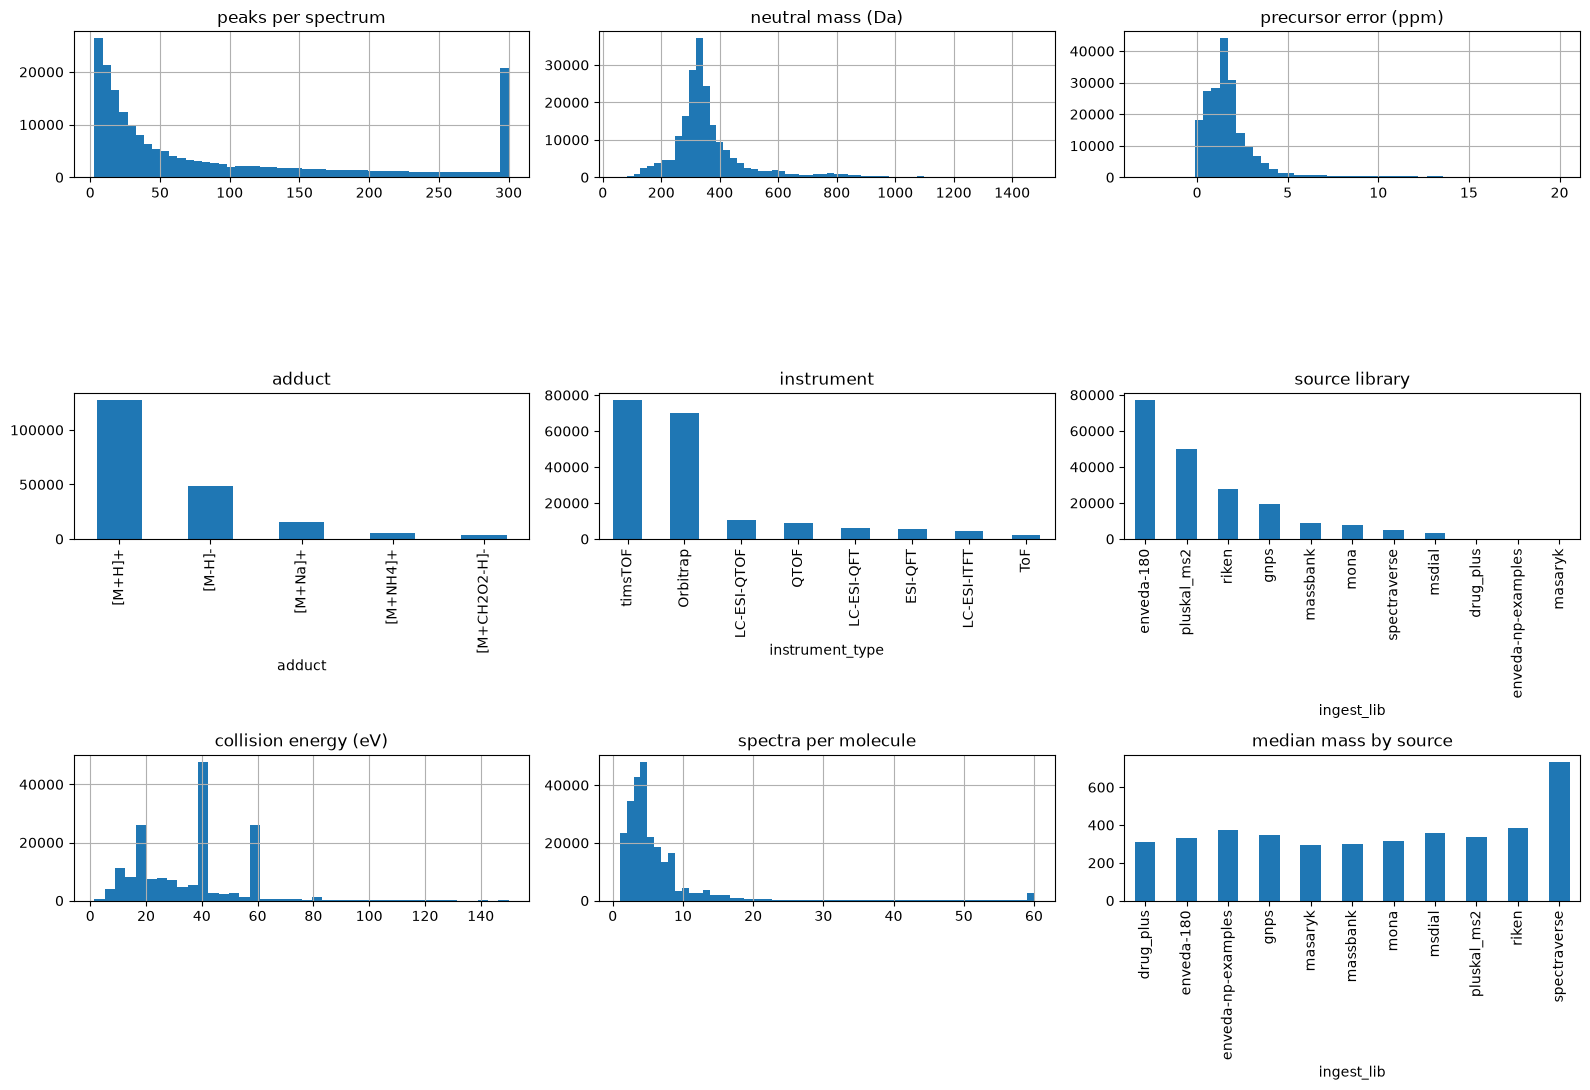

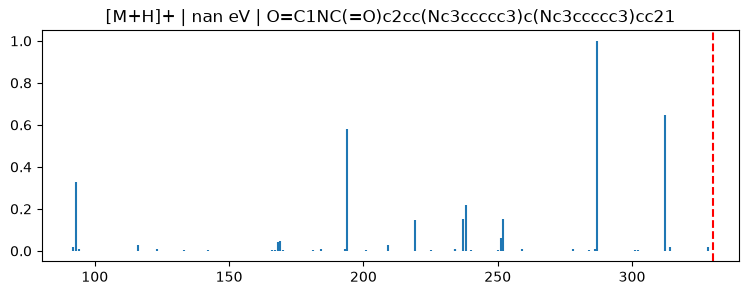

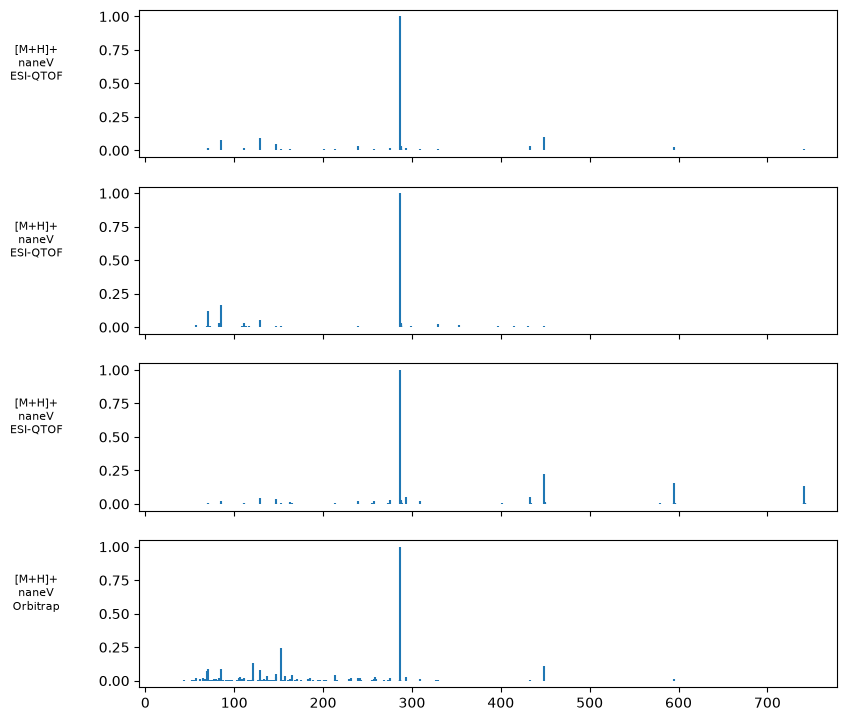

In [11]:
d = df.sample(min(200_000, len(df)), random_state=0)    # plotting 1.7M rows is slow and unnecessary

fig, ax = plt.subplots(3, 3, figsize=(16, 11))
d.num_peaks.clip(upper=300).hist(bins=50, ax=ax[0,0]);       ax[0,0].set_title("peaks per spectrum")
d.neutral_mass.hist(bins=60, ax=ax[0,1]);                    ax[0,1].set_title("neutral mass (Da)")
d.precursor_error_ppm.hist(bins=50, ax=ax[0,2]);             ax[0,2].set_title("precursor error (ppm)")
d.adduct.value_counts().plot.bar(ax=ax[1,0]);                ax[1,0].set_title("adduct")
d.instrument_type.value_counts().head(8).plot.bar(ax=ax[1,1]); ax[1,1].set_title("instrument")
d.ingest_lib.value_counts().plot.bar(ax=ax[1,2]);            ax[1,2].set_title("source library")
d.collision_energy_ev.clip(upper=150).hist(bins=40, ax=ax[2,0]); ax[2,0].set_title("collision energy (eV)")
df.groupby(PROV_KEY).size().clip(upper=60).hist(bins=60, ax=ax[2,1]); ax[2,1].set_title("spectra per molecule")
d.groupby("ingest_lib").neutral_mass.median().plot.bar(ax=ax[2,2]); ax[2,2].set_title("median mass by source")
plt.tight_layout()

# one spectrum, precursor marked
r = df.iloc[0]
plt.figure(figsize=(9, 3))
plt.vlines(r.ms2_mzs, 0, r.ms2_normalized_intensities)
plt.axvline(r.precursor_mz, color="r", ls="--")
plt.title(f"{r.adduct} | {r.collision_energy_ev:.0f} eV | {r[SMILES_COL][:50]}")

# the SAME molecule measured under different conditions
k = df.groupby(PROV_KEY).size().sort_values().index[-500]
ex = df[df[PROV_KEY] == k].head(4)
fig, axs = plt.subplots(len(ex), 1, figsize=(9, 2.2 * len(ex)), sharex=True)
for a, (_, r) in zip(np.atleast_1d(axs), ex.iterrows()):
    a.vlines(r.ms2_mzs, 0, r.ms2_normalized_intensities)
    a.set_ylabel(f"{r.adduct}\n{r.collision_energy_ev:.0f}eV\n{r.instrument_type}",
                 rotation=0, labelpad=45, fontsize=8)

### Working dataset and leakage-proof split

**Goal:** Build the evaluation set so validation molecules are structurally unseen. This is the core of the experimental design.

**Found**
- Cap each source at 5,000 molecules and each molecule at 3 spectra, so `enveda-180` doesn't swamp everything.
- Compute the **canonical key** (InChIKey14 of the tautomer-canonical molecule, as in the metric) and the stereo-free **Murcko scaffold** (ring system plus linkers) once per unique SMILES.
- Re-apply the cap on the canonical key. Give each acyclic molecule its own scaffold group.
- `GroupShuffleSplit` 80/20 by scaffold, hard-remove any val molecule also in train, `assert` zero overlap.
- **76,975 spectra / 30,323 molecules before canonicalisation, 76,248 / 29,964 after** (359 merged, 0 parse failures, ~15.5 min).
- **0 overlapping molecules before the hard fix**, so the scaffold fix works.
- **61,701 train / 14,547 val rows** (19.1% val); acyclic share balanced (14.5% / 15.0%), so bugs #2 and #3 have not returned.

> **Decisions**
> - Every score below is on **unseen scaffolds**, so it measures generalisation, not memorisation.
> - The subset is only ~12% of all molecules: compare versions on this split, don't read absolute numbers as final.

In [17]:
PER_SRC, PER_MOL = 5_000, 3

# 1) cap molecules per source so enveda-180 doesn't swamp everything
mol_tab = df.groupby(PROV_KEY, as_index=False).ingest_lib.first()
keys = np.unique(np.concatenate([
    g[PROV_KEY].sample(min(len(g), PER_SRC), random_state=42).values
    for _, g in mol_tab.groupby("ingest_lib")
]))

# 2) keep at most PER_MOL spectra per molecule (provisional, by the provided key)
sub = (df[df[PROV_KEY].isin(keys)]
       .sample(frac=1, random_state=0)
       .groupby(PROV_KEY).head(PER_MOL)
       .reset_index(drop=True))
print(len(sub), "spectra |", sub[PROV_KEY].nunique(), "molecules (before canonicalisation)")

# 3) canonical key (same recipe as the metric) + stereo-free scaffold, once per unique SMILES
taut = rdMolStandardize.TautomerEnumerator()

def key_and_scaffold(smi):
    try:
        m = Chem.MolFromSmiles(smi)
        if m is None:
            return None, None
        mc = taut.Canonicalize(m)                         # canonical tautomer, as in the metric
        key = Chem.MolToInchiKey(mc)[:14]                 # connectivity-only key
        ms = Chem.Mol(mc)
        Chem.RemoveStereochemistry(ms)                    # scaffold must ignore stereo
        scaf = MurckoScaffold.MurckoScaffoldSmiles(mol=ms)
        return key, scaf
    except Exception:
        return None, None

res = {s: key_and_scaffold(s) for s in tqdm(sub[SMILES_COL].unique())}   # ~20 min
print("failed to parse:", sum(v[0] is None for v in res.values()), "of", len(res))
sub["key"]      = sub[SMILES_COL].map(lambda s: res[s][0])
sub["scaffold"] = sub[SMILES_COL].map(lambda s: res[s][1])
sub = sub.dropna(subset=["key", "scaffold"]).reset_index(drop=True)

# 3b) re-apply the per-molecule cap on the canonical key
sub = sub.groupby("key").head(PER_MOL).reset_index(drop=True)
print(len(sub), "spectra |", sub.key.nunique(), "molecules (after canonicalisation)")

# 3c) one scaffold per molecule, so a molecule can never straddle the split
sub["scaffold"] = sub.groupby("key").scaffold.transform(lambda s: s.mode().iloc[0])

# 3d) acyclic molecules all share the empty scaffold "", which would form one giant group
#     that lands entirely on one side. Give each acyclic molecule its own group instead.
empty = sub.scaffold == ""
sub["is_acyclic"] = empty
sub.loc[empty, "scaffold"] = "acyclic_" + sub.loc[empty, "key"]

# 4) split by scaffold
gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=42)
tr_i, va_i = next(gss.split(sub, groups=sub.scaffold))
tr, va = sub.iloc[tr_i].reset_index(drop=True), sub.iloc[va_i].reset_index(drop=True)

# 5) hard guarantee: remove any validation row whose molecule is also in train
overlap = set(tr.key) & set(va.key)
print("overlapping molecules before fix:", len(overlap),
      "| val rows affected:", va.key.isin(overlap).sum())
va = va[~va.key.isin(overlap)].reset_index(drop=True)
assert len(set(tr.key) & set(va.key)) == 0, "train/val still share molecules"

print(len(tr), "train |", len(va), "val | molecule overlap:", len(set(tr.key) & set(va.key)))
print(f"val share of rows: {len(va) / (len(tr) + len(va)):.1%}")
print("acyclic share  all:", sub.is_acyclic.mean().round(3),
      "| train:", tr.is_acyclic.mean().round(3),
      "| val:", va.is_acyclic.mean().round(3))

76975 spectra | 30323 molecules (before canonicalisation)


100%|██████████| 30764/30764 [15:34<00:00, 32.92it/s]  


failed to parse: 0 of 30764
76248 spectra | 29964 molecules (after canonicalisation)
overlapping molecules before fix: 0 | val rows affected: 0
61701 train | 14547 val | molecule overlap: 0
val share of rows: 19.1%
acyclic share  all: 0.146 | train: 0.145 | val: 0.15


### Spectrum features

**Goal:** Turn each variable-length peak list into a fixed 1,019-column vector.

**Found**
- 1,000 bins of 1 Da holding `sqrt(intensity)`, L2-normalised.
- Numeric extras: neutral mass/1000, collision energy/100 (missing -> train median), `ce_multi`.
- One-hots for adduct, instrument (top 8 + "other") and ionization mode. Columns are fixed from **train only**.
- `Xtr` shape: **(61,701, 1,019)**.

> **Decisions**
> - This is the representation v0.2+ will replace. Its limits are the obvious single-change experiments:
> - 1 Da bins can't separate fragments closer than 1 Da; they ignore **neutral losses** (precursor minus fragment), which are more informative for natural products; and the axis stops at 1,000.

In [18]:
MAX_MZ, BIN = 1000, 1.0
NB = int(MAX_MZ / BIN)

def spec_vec(mz, it):
    v = np.zeros(NB, np.float32)
    idx = (mz / BIN).astype(int)
    ok = (idx >= 0) & (idx < NB)
    np.add.at(v, idx[ok], np.sqrt(it[ok]))      # add (not assign): two peaks can share a bin
    return v / (np.linalg.norm(v) + 1e-9)       # unit length

META = ["ionization_mode", "instrument_type", "adduct"]
top_inst = tr.instrument_type.value_counts().head(8).index
def meta_frame(d):
    m = d[META].copy()
    m["instrument_type"] = m.instrument_type.where(m.instrument_type.isin(top_inst), "other")
    return pd.get_dummies(m)
meta_cols = meta_frame(tr).columns              # fix the columns from TRAIN only
ce_med = tr.collision_energy_ev.median()

def build_X(d):
    S = np.stack([spec_vec(m, i) for m, i in zip(d.ms2_mzs, d.ms2_normalized_intensities)])
    M = meta_frame(d).reindex(columns=meta_cols, fill_value=0).values.astype(np.float32)
    num = np.c_[d.neutral_mass / MAX_MZ,
                d.collision_energy_ev.fillna(ce_med) / 100,
                d.ce_multi].astype(np.float32)
    return np.hstack([S, num, M])               # spectrum block = columns 0..NB-1

Xtr, Xva = build_X(tr), build_X(va)
print(Xtr.shape)

(61701, 1019)


### Targets and candidate library

**Goal:** Compute a Morgan fingerprint and exact mass for every molecule, and define the pool we may rank (the library).

**Found**
- **Morgan fingerprint:** a 1,024-bit 0/1 vector flagging substructures within 2 bonds of each atom.
- Library = molecules appearing in train: **24,274 molecules**.
- Fingerprint density is **0.044** (about 45 of 1,024 bits set), so targets are very sparse.

> **Decisions**
> - By construction **no validation molecule is in this library**, which explains the zeros in methods B-D.
> - Sparse targets suit Ridge poorly (independent bits, squared loss): v0.2 candidates are per-bit classifiers or a different loss.

In [19]:
fpgen = rdFingerprintGenerator.GetMorganGenerator(radius=2, fpSize=1024)

mols_u = sub.drop_duplicates("key").reset_index(drop=True)      # one row per molecule
mol_objs = [Chem.MolFromSmiles(s) for s in mols_u[SMILES_COL]]
FP = np.stack([fpgen.GetFingerprintAsNumPy(m) for m in mol_objs]).astype(np.float32)
mass_u = np.array([Descriptors.ExactMolWt(m) for m in mol_objs])
row_of = pd.Series(np.arange(len(mols_u)), index=mols_u.key)

Ytr = FP[row_of[tr.key].values]                # training targets: one fingerprint per spectrum

in_train = mols_u.key.isin(set(tr.key)).values
lib_keys, lib_fp, lib_mass = mols_u.key.values[in_train], FP[in_train], mass_u[in_train]

unit = lambda A: A / (np.linalg.norm(A, axis=1, keepdims=True) + 1e-9)
lib_fp_n = unit(lib_fp)
print("library size:", len(lib_keys), "| fingerprint density:", FP.mean().round(3))

library size: 24274 | fingerprint density: 0.044


### Evaluation setup

**Goal:** Define `mrr_at_25`, a fast `top_k`, and a fixed 2,000-spectrum validation subset.

**Found**
- No output. The subset is now reproducible (`default_rng(42)`).
- It is sampled by *spectrum*, so molecules with more val spectra are over-represented relative to the competition's one-prediction-per-molecule scoring.
- `rng` is reused by later random baselines, so their numbers shift with cell order.

> **Decision:** All later scores use these same 2,000 queries.

In [24]:
rng = np.random.default_rng(42)   # fixed seed so the eval subset is reproducible

def mrr_at_25(ranked, true):
    return float(np.mean([
        1 / (c[:25].index(t) + 1) if t in c[:25] else 0.0
        for c, t in zip(ranked, true)
    ]))

def top_k(S, k=25):                                  # indices of the k largest per row, best first
    idx = np.argpartition(-S, k, axis=1)[:, :k]
    order = np.argsort(-np.take_along_axis(S, idx, 1), axis=1)
    return np.take_along_axis(idx, order, 1)

vi = rng.choice(len(va), size=min(2000, len(va)), replace=False)
Xv, true_v, mass_v = Xva[vi], va.key.values[vi].tolist(), va.neutral_mass.values[vi]

### Method A: frequency floor

**Goal:** Predict the 25 most common training molecules for every query, to check that popularity doesn't score.

**Found**
- **MRR@25 = 0.0000**

> **Decision:** Confirms no popular-molecule shortcut. This is the sanity floor.

In [25]:
top25 = tr.key.value_counts().index[:25].tolist()
score_A = mrr_at_25([top25] * len(true_v), true_v)
print("A  most-common-molecules:", score_A)

A  most-common-molecules: 0.0


### Method B: cosine library match

**Goal:** Classic spectral-library search: average the training spectra per molecule and rank by cosine similarity to the query.

**Found**
- **MRR@25 = 0.0000**

> **Decisions**
> - Zero by construction, since the val molecule is never in a train-only library.
> - Library matching alone can't identify unseen molecules; we must predict structure or search a larger structure database.

In [26]:
Xlib = (pd.DataFrame(Xtr[:, :NB]).groupby(tr.key.values).mean()
          .reindex(lib_keys).values)                 # average spectrum per library molecule
S = Xv[:, :NB] @ unit(Xlib).T                        # cosine similarity, every val spectrum x every molecule
rank_B = [list(lib_keys[r]) for r in top_k(S)]
score_B = mrr_at_25(rank_B, true_v)
print("B  cosine library match:", score_B)

B  cosine library match: 0.0


### Method C: predict a fingerprint, rank the library

**Goal:** Fit `Ridge(alpha=1)` from features to fingerprint bits, then rank library molecules by cosine similarity to the predicted fingerprint.

**Found**
- **MRR@25 = 0.0000**

> **Decisions**
> - Zero for the same reason as B. The model may still predict good substructures, but this score can't show it.
> - This motivates the oracle experiments below.

In [35]:
import torch, torch.nn as nn
torch.manual_seed(42)
dev = "cuda" if torch.cuda.is_available() else "mps" if torch.backends.mps.is_available() else "cpu"

# early-stopping holdout carved from TRAIN, grouped by scaffold; val stays untouched
i_fit, i_es = next(GroupShuffleSplit(1, test_size=0.1, random_state=42).split(Xtr, groups=tr.scaffold))
T = lambda a: torch.tensor(a, dtype=torch.float32, device=dev)
Xf, Yf, Xe, Ye = T(Xtr[i_fit]), T(Ytr[i_fit]), T(Xtr[i_es]), T(Ytr[i_es])

net = nn.Sequential(
    nn.Linear(Xtr.shape[1], 1024), nn.ReLU(), nn.Dropout(0.3),
    nn.Linear(1024, 1024), nn.ReLU(), nn.Dropout(0.3),
    nn.Linear(1024, 1024),                       # logits; sigmoid lives inside the loss
).to(dev)
opt, lossf = torch.optim.AdamW(net.parameters(), lr=1e-3, weight_decay=1e-2), nn.BCEWithLogitsLoss()

best, bad, best_state = 1e9, 0, None
for ep in range(100):
    net.train()
    for b in torch.randperm(len(Xf), device=dev).split(256):
        opt.zero_grad(); lossf(net(Xf[b]), Yf[b]).backward(); opt.step()
    net.eval()
    with torch.no_grad(): e = lossf(net(Xe), Ye).item()
    if e < best - 1e-4: best, bad, best_state = e, 0, {k: v.clone() for k, v in net.state_dict().items()}
    else:
        bad += 1
        if bad >= 8: break
net.load_state_dict(best_state); print("stopped at epoch", ep, "| best holdout BCE", round(best, 4))

with torch.no_grad(): P = unit(torch.sigmoid(net(T(Xv))).cpu().numpy())


stopped at epoch 20 | best holdout BCE 0.1248


In [27]:
reg = Ridge(alpha=1.0).fit(Xtr, Ytr)                 # spectrum features -> 1024 fingerprint bits
P = unit(reg.predict(Xv))

def rank_by_fp(P, keys, fp_n, lib_mass=None, query_mass=None, tol_ppm=10):
    S = P @ fp_n.T
    if lib_mass is not None:                         # optional mass filter (Method D)
        err = np.abs(lib_mass[None, :] - query_mass[:, None]) / query_mass[:, None] * 1e6
        S = np.where(err <= tol_ppm, S, -np.inf)
    return [list(keys[r]) for r in top_k(S)]

score_C = mrr_at_25(rank_by_fp(P, lib_keys, lib_fp_n), true_v)
print("C  fingerprint predict + rank:", score_C)

C  fingerprint predict + rank: 0.0


### Method D: C plus 10 ppm mass filter

**Goal:** Restrict ranking to library molecules within 10 ppm of the query's neutral mass (about +/-0.003 Da at 300 Da).

**Found**
- **MRR@25 = 0.0000**

> **Decisions**
> - Closes the train-only branch: **the candidate pool is the biggest lever.**
> - The remaining cells use an "oracle" pool to measure ranking quality.

In [36]:
score_D = mrr_at_25(
    rank_by_fp(P, lib_keys, lib_fp_n, lib_mass=lib_mass, query_mass=mass_v, tol_ppm=10),
    true_v)
print("D  C + mass filter:", score_D)

D  C + mass filter: 0.0


### Methods E1 / E2: oracle library

**Goal:** Add the validation molecules to the pool (cheating on purpose) to separate ranking quality from pool coverage.

**Found**
- **E1** (fingerprint ranking, no mass filter): **0.0043**, ~40x chance but very low.
- **E2** (plus 10 ppm window): **0.6751**.
- The mass window turns a 30k-way ranking into a median ~3-way one.

> **Decisions**
> - The model alone is weak; mass does most of the work.
> - E2 is **inflated by the small pool**. Judge changes on the 230k benchmark, not on this.

In [37]:
all_keys, all_fp_n, all_mass = mols_u.key.values, unit(FP), mass_u     # library now includes val molecules

score_E1 = mrr_at_25(rank_by_fp(P, all_keys, all_fp_n), true_v)
score_E2 = mrr_at_25(
    rank_by_fp(P, all_keys, all_fp_n, lib_mass=all_mass, query_mass=mass_v), true_v)
print("E1 oracle library, no mass filter:", score_E1)
print("E2 oracle library + mass filter  :", score_E2)

pd.Series({"A floor": score_A, "B cosine": score_B, "C fp-rank": score_C, "D C+mass": score_D,
           "E1 oracle": score_E1, "E2 oracle+mass": score_E2}).round(4)

E1 oracle library, no mass filter: 0.009206525496889106
E2 oracle library + mass filter  : 0.6937677280536801


A floor           0.0000
B cosine          0.0000
C fp-rank         0.0000
D C+mass          0.0000
E1 oracle         0.0092
E2 oracle+mass    0.6938
dtype: float64

### How much does the model add beyond mass? (E3)

**Goal:** Count candidates per query, check how often the truth falls outside the window, and score a **random order** inside it. E2 minus E3 is the model's real contribution.

**Found**
- Candidates per query: mean 4.67, **median 3**, max 27, min 0.
- **2.25%** of queries have the true molecule outside the window.
- **E3 = 0.5954**, so the model adds only **0.080**.

> **Decisions**
> - Most of the apparent skill at 30k is mass, not the model.
> - The 2.25% misses are a hard ceiling for this setup, which motivates the tolerance sweep (P3).
> - CONTEXT.md reports 0.5844 / 1.65% because the original eval sample wasn't seeded. Use this notebook's seeded numbers as the reference.

In [38]:
# candidates left in the 10 ppm mass window, per validation query
q = mass_v[:, None].astype(np.float32)
err = np.abs(all_mass[None, :].astype(np.float32) - q) / q * 1e6
in_win = err <= 10
n_cand = in_win.sum(1)
print(pd.Series(n_cand).describe())
print("queries with the true molecule outside the window:",
      np.mean([not in_win[i, np.where(all_keys == t)[0][0]] for i, t in enumerate(true_v)]).round(4))

# E3: oracle library + mass window + RANDOM order (what mass alone gives you)
S_rand = np.where(in_win, rng.random(in_win.shape, dtype=np.float32), -np.inf)
score_E3 = mrr_at_25([list(all_keys[r]) for r in top_k(S_rand)], true_v)
print("E3 oracle + mass + random order:", score_E3)
print("model contribution (E2 - E3):  ", score_E2 - score_E3)

count    2000.000000
mean        4.669500
std         4.092388
min         0.000000
25%         2.000000
50%         3.000000
75%         6.000000
max        27.000000
dtype: float64
queries with the true molecule outside the window: 0.0225
E3 oracle + mass + random order: 0.5879108300389841
model contribution (E2 - E3):   0.105856898014696


### Why does the truth fall outside the window?

**Goal:** Compute the signed ppm error to the true molecule and break window misses down by adduct and source.

**Found**
- Error is centred (median +0.06 ppm, mean +0.23), so adduct arithmetic is unbiased.
- By adduct: **[M+Na]+ 10.5%**, [M+H]+ 2.0%, [M-H]- 1.3%, others 0.
- By source: **`riken` 13.5%**, `mona` 4.4%, `gnps` 1.7%, `massbank` 1.3%, others 0.
- Miss sizes run from 10.1 to 20.1 ppm: inside the 20 ppm cleaning cutoff but outside the 10 ppm window.

> **Decisions**
> - Nothing is wrong with the adduct shifts; the problem is measurement noise in `riken`-type data.
> - A source- or adduct-aware tolerance beats one global 10 ppm (P3's question). Don't over-tune to `riken`: the test domain is likely accurate timsTOF.

In [39]:
pos = {k: i for i, k in enumerate(all_keys)}
true_mass = np.array([all_mass[pos[t]] for t in true_v])
ppm = (mass_v - true_mass) / true_mass * 1e6
va_v = va.iloc[vi].reset_index(drop=True)
out = np.abs(ppm) > 10

print(pd.Series(ppm).describe())
print("misses by adduct rate:\n", pd.Series(out).groupby(va_v.adduct.values).mean().round(4))
print("misses by source rate:\n", pd.Series(out).groupby(va_v.ingest_lib.values).mean().round(4))
print("miss sizes (ppm):", np.sort(np.abs(ppm[out]))[:15].round(1), "...", np.sort(np.abs(ppm[out]))[-5:].round(1))

count    2000.000000
mean        0.229477
std         2.824582
min       -18.387119
25%        -0.080869
50%         0.055688
75%         1.043246
max        20.091995
dtype: float64
misses by adduct rate:
 [M+CH2O2-H]-    0.0000
[M+H]+          0.0204
[M+NH4]+        0.0000
[M+Na]+         0.1048
[M-H]-          0.0130
dtype: float64
misses by source rate:
 drug_plus             0.0000
enveda-180            0.0000
enveda-np-examples    0.0000
gnps                  0.0166
massbank              0.0132
mona                  0.0440
msdial                0.0000
pluskal_ms2           0.0000
riken                 0.1346
spectraverse          0.0000
dtype: float64
miss sizes (ppm): [10.1 10.1 10.2 10.6 10.6 11.1 11.1 11.1 11.3 11.7 11.7 11.8 12.  12.1
 12.5] ... [16.7 18.2 18.4 19.  20.1]


### Scaling benchmark: grow the pool with decoys

**Goal:** Add up to 200,000 real unused molecules as decoys (keys prefixed `d_`, true molecule always present) and re-score inside the 10 ppm window as the pool grows from 30k to 230k.

**Found**
- Both curves fall roughly with the log of the pool.
- **The model-minus-random gap is flat at ~0.09-0.10**: the Ridge ranker doesn't improve as the list gets harder.

| Pool | Cand/query | Model | Random | Model - random |
|---:|---:|---:|---:|---:|
| 29,964 | 4.7 | 0.6759 | 0.5878 | 0.088 |
| 39,964 | 6.4 | 0.6275 | 0.5375 | 0.090 |
| 79,964 | 13.7 | 0.5265 | 0.4327 | 0.094 |
| 129,964 | 22.7 | 0.4638 | 0.3665 | 0.097 |
| 229,964 | 40.6 | 0.4021 | 0.3042 | 0.098 |

> **Decisions**
> - This table is the **benchmark every future version is judged against** (model score, model-minus-random, median candidates/query).
> - Real databases are far bigger than 230k, so ranking quality will matter much more there.
> - Caveats: decoys come from this competition's own molecules, skip tautomer canonicalisation, and `rng` is shared. Treat differences under ~0.01 as noise until evaluation is deterministic (this run: 0.4021 at 230k vs 0.3956 in CONTEXT.md).

100%|██████████| 200000/200000 [00:29<00:00, 6701.07it/s]


decoys: 200000


,pool,cand_per_query,model,random
0,29964,4.7,0.6940,0.5949
1,39964,6.4,0.6460,0.5310
2,79964,13.7,0.5477,0.4249
3,129964,22.7,0.4868,0.3724
4,229964,40.6,0.4231,0.3100


<Axes: title={'center': 'MRR@25 vs pool size'}, xlabel='pool'>

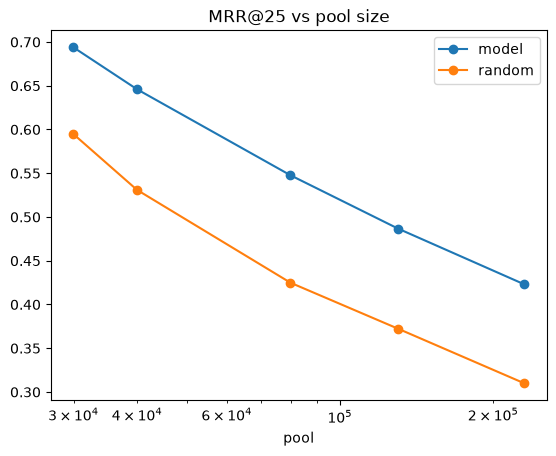

In [40]:
# 1) decoy pool: molecules NOT in your subsample (provided key; no tautomer step, to save time)
used = set(sub[PROV_KEY])
dec = (df[~df[PROV_KEY].isin(used)]
       .drop_duplicates(PROV_KEY)[[PROV_KEY, SMILES_COL]]
       .sample(200_000, random_state=0).reset_index(drop=True))

fps, ms, ok = [], [], []
for s in tqdm(dec[SMILES_COL]):
    m = Chem.MolFromSmiles(s)
    if m is None: ok.append(False); continue
    fps.append(fpgen.GetFingerprintAsNumPy(m)); ms.append(Descriptors.ExactMolWt(m)); ok.append(True)
dec = dec[np.array(ok)].reset_index(drop=True)
dec_fp_n = unit(np.array(fps, np.float32)); dec_mass = np.array(ms)
dec_keys = np.array(["d_" + k for k in dec[PROV_KEY]])        # prefix so they can never equal a true key
print("decoys:", len(dec))

# 2) score a pool using only the candidates inside each mass window
def rr(cands, t):
    return 1 / (cands.index(t) + 1) if t in cands else 0.0

def eval_pool(keys, fp_n, mass, tol_ppm=10):
    order = np.argsort(mass); m_sorted = mass[order]
    sm, sr, nc = [], [], []
    for i in range(len(true_v)):
        q = mass_v[i]; w = q * tol_ppm * 1e-6
        lo, hi = np.searchsorted(m_sorted, [q - w, q + w])
        idx = order[lo:hi]; nc.append(len(idx))
        if len(idx) == 0:
            sm.append(0.0); sr.append(0.0); continue
        s = fp_n[idx] @ P[i]
        sm.append(rr([keys[j] for j in idx[np.argsort(-s)[:25]]], true_v[i]))
        sr.append(rr([keys[j] for j in rng.permutation(idx)[:25]], true_v[i]))
    return np.mean(nc), np.mean(sm), np.mean(sr)

# 3) grow the pool
rows = []
for n in [0, 10_000, 50_000, 100_000, len(dec)]:
    keys = np.concatenate([all_keys, dec_keys[:n]])
    fp_n = np.vstack([all_fp_n, dec_fp_n[:n]])
    mass = np.concatenate([all_mass, dec_mass[:n]])
    c, m_, r_ = eval_pool(keys, fp_n, mass)
    rows.append(dict(pool=len(keys), cand_per_query=round(c, 1), model=round(m_, 4), random=round(r_, 4)))
res_scale = pd.DataFrame(rows); display(res_scale)
res_scale.plot(x="pool", y=["model", "random"], logx=True, marker="o", title="MRR@25 vs pool size")

### Save the benchmark and decoys

**Goal:** Persist the benchmark table (`bench_v1.csv`, tagged `v1_ridge_1da`) and the decoy arrays so later versions score on the identical 230k pool.

**Found**
- No output. Files land in the current directory (the untracked `bench_v1.csv` and `dec_*.npy` in the repo root).

> **Decision:** Move them into `artifacts/` and append new versions' rows to the same benchmark table.

In [33]:
bench = pd.DataFrame(res_scale); bench["version"] = "v1_ridge_1da"
bench.to_csv("bench_v1.csv", index=False)
np.save("dec_fp_n.npy", dec_fp_n); np.save("dec_mass.npy", dec_mass); np.save("dec_keys.npy", dec_keys)

# P1 + P2 — read the test file, then understand the data
Everything below is **EDA only**: no model changes, no effect on the v0.1 results above. It is self-contained (reads only the small
metadata columns of `train.parquet`, never the full peak arrays) and saves figures to `reports/`. Run the cells in order, from the repo root.

### Setup
**Why:** `df` above holds 2.5M peak arrays. These questions only need adduct/source/mass/peak-count columns, so we load just those (seconds, not minutes)
and fetch the actual peaks for a few hundred spectra on demand with `read_spectra`.

In [ ]:
# ---- P1/P2 setup: metadata only (no peak arrays) + the test file ----------------------------------
# Why: the full train frame (cell 9) holds 2.5M peak arrays (~GBs). EDA questions about adducts, sources,
# masses and peak counts only need the small columns, so we read just those and fetch peaks on demand.
import pyarrow.parquet as pq
from rdkit.Chem import rdMolDescriptors

REPORTS = "reports"; os.makedirs(REPORTS, exist_ok=True)
SRC = "ingest_lib"
META_COLS = ["ingest_lib", "normalized_smiles", "inchikey14", "molecular_formula", "ionization_mode",
             "instrument_type", "adduct", "precursor_mz", "precursor_error_ppm", "num_peaks",
             "collision_energy_orig"]
meta = pq.read_table(TRAIN_PATH, columns=META_COLS).to_pandas()   # row order == file order (used by read_spectra)
test = pd.read_parquet(TEST_PATH)

# adduct shifts: the v0.1 table plus the two extra adducts that occur in test ([M+K]+, [M+Cl]-)
SHIFT = {"[M+H]+": 1.007276, "[M-H]-": -1.007276, "[M+Na]+": 22.989218, "[M+NH4]+": 18.033823,
         "[M+CH2O2-H]-": 44.997655, "[M+K]+": 38.963158, "[M+Cl]-": 34.969402}
for d_ in (meta, test):
    d_["neutral_mass"] = d_.precursor_mz - d_.adduct.map(SHIFT)   # NaN for dimers / water-loss adducts
test["num_peaks"] = test.ms2_mzs.map(len)

def ce_scheme(s):
    """'-60,-40,-20' and '20,40,60' are the same stepped scheme (sign = polarity); '20;50' -> '20/50'."""
    try:
        v = sorted({abs(float(x)) for x in str(s).replace(";", ",").split(",") if x.strip()})
        return "/".join(f"{x:g}" for x in v) or "NA"
    except ValueError:
        return "NA"
for d_ in (meta, test):
    m_ = {s: ce_scheme(s) for s in d_.collision_energy_orig.astype(str).unique()}
    d_["ce_scheme"] = d_.collision_energy_orig.astype(str).map(m_)

def read_spectra(row_ids):
    """Fetch peak arrays for selected rows of train.parquet (positions in `meta`), one row group at a time."""
    pf = pq.ParquetFile(TRAIN_PATH)
    starts = np.cumsum([0] + [pf.metadata.row_group(i).num_rows for i in range(pf.num_row_groups)])
    row_ids = np.asarray(sorted(set(row_ids))); out = {}
    for g in range(pf.num_row_groups):
        sel = row_ids[(row_ids >= starts[g]) & (row_ids < starts[g + 1])]
        if len(sel) == 0: continue
        t_ = pf.read_row_group(g, columns=["ms2_mzs", "ms2_normalized_intensities"]).take(sel - starts[g])
        for r, mz, it in zip(sel, t_["ms2_mzs"].to_pylist(), t_["ms2_normalized_intensities"].to_pylist()):
            out[int(r)] = (np.asarray(mz, float), np.asarray(it, float))
    return out

def binned(mz, it, nb=1000):
    """Same recipe as v0.1: 1 Da bins, sqrt(intensity), unit length."""
    v = np.zeros(nb); idx = mz.astype(int); ok = (idx >= 0) & (idx < nb)
    np.add.at(v, idx[ok], np.sqrt(it[ok]))
    return v / (np.linalg.norm(v) + 1e-9)

order = meta[SRC].value_counts().index.tolist()          # sources, biggest first (used by every plot)
print(f"train meta {meta.shape} | test {test.shape}")


### P1 — what does the test file actually contain?
**Why:** it decides the whole strategy. The Kaggle Data tab is client-rendered and could not be fetched, but `test.parquet` is in `data/`, so we can answer
questions (b), (c), (d, partly) and (e) directly from it. Questions (a) external data and (f) notebook rules need the Rules tab text — see `docs/CONTEXT.md` section 2.

In [ ]:
# ---- P1: what the test file tells us (answers to questions b, c, d, e) --------------------------
g = test.groupby("molecule_id")
print("TEST columns:", [c for c in test.columns if not c.startswith("ms2")], "+ ms2 arrays")
print("  no SMILES, no molecular_formula, no precursor_error_ppm, no ingest_lib  ->  (b) only precursor_mz + adduct\n")

print(f"(c) {len(test)} spectra, {test.molecule_id.nunique()} molecules; spectra/molecule: "
      f"mean {g.size().mean():.2f}, median {g.size().median():.0f}, min {g.size().min()}, max {g.size().max()}")
print("    molecules with >1 adduct:", (g.adduct.nunique() > 1).sum(), "| with both polarities:",
      (g.ionization_mode.nunique() > 1).sum(), "| with a stepped-CE spectrum:",
      g.ce_scheme.apply(lambda s: s.str.contains("/").any()).sum())

print("\n(e) instrument:", test.instrument_type.value_counts().to_dict())
print("    adducts:   ", test.adduct.value_counts().to_dict())
print("    CE schemes:", test.ce_scheme.value_counts().to_dict())
print("    adducts missing from the v0.1 table:", int((~test.adduct.isin(["[M+H]+", "[M-H]-", "[M+Na]+", "[M+NH4]+", "[M+CH2O2-H]-"])).sum()), "spectra")

# neutral mass: every spectrum of a molecule should imply the SAME neutral mass, whatever its adduct
multi = g.adduct.nunique() > 1
spread_ppm = ((g.neutral_mass.max() - g.neutral_mass.min()) / g.neutral_mass.median() * 1e6)[multi]
print(f"\nneutral mass per test molecule: median {g.neutral_mass.median().median():.1f} Da, "
      f"range {g.neutral_mass.median().min():.1f}-{g.neutral_mass.median().max():.1f}")
print(f"agreement of neutral mass across a molecule's different adducts ({multi.sum()} molecules): "
      f"median {spread_ppm.median():.2f} ppm, 99th pct {spread_ppm.quantile(.99):.2f} ppm, max {spread_ppm.max():.2f} ppm")

print(f"\npeaks per test spectrum: median {test.num_peaks.median():.0f}, 95th pct {test.num_peaks.quantile(.95):.0f}, "
      f"max {test.num_peaks.max()} | {np.mean(test.num_peaks > 500):.1%} exceed v0.1's 500-peak cap "
      f"(those would have been DROPPED by the v0.1 filter; test cannot be filtered)")

# is the test domain the enveda-180 domain? compare the acquisition setup, spectrum by spectrum
e180 = meta[meta[SRC] == "enveda-180"]
print("\nenveda-180 vs test:")
print("  instrument  :", e180.instrument_type.value_counts().head(2).to_dict(), "vs", test.instrument_type.value_counts().to_dict())
print("  neutral mass: mean/std", round(e180.neutral_mass.mean(), 1), "/", round(e180.neutral_mass.std(), 1),
      "vs", round(test.neutral_mass.mean(), 1), "/", round(test.neutral_mass.std(), 1))
print("  CE schemes  :", e180.ce_scheme.value_counts(normalize=True).head(4).round(3).to_dict(), "\n               vs",
      test.ce_scheme.value_counts(normalize=True).head(4).round(3).to_dict())

# real measurement error on this instrument (needed for the mass-window policy, P3)
a = e180.precursor_error_ppm.abs()
print(f"  enveda-180 |precursor error|: median {a.median():.2f} ppm, 95th {a.quantile(.95):.2f}, 99th {a.quantile(.99):.2f}")


### P2.1 — the same molecule, measured differently (`p2_1a_*`, `p2_1b_*`)
**Why:** the model has to map *spectrum -> structure*, but one molecule gives many different spectra. Left: one train molecule across sources. Right: one test molecule at 20/40/60 eV.
Low energy keeps the precursor and a few big fragments; high energy shatters it into many small ones. The second figure puts numbers on this: cosine similarity of spectra of the
same molecule vs different molecules, and the collision-energy effect on one instrument.

In [ ]:
# ---- P2.1  the SAME molecule, measured differently ------------------------------------------------
# Left: one train molecule in [M+H]+ from several sources/instruments/collision energies.
# Right: one TEST molecule at 20/40/60 eV on the same instrument. Peaks are normalised intensities; red line = precursor.
rng = np.random.default_rng(42)
pos = meta[meta.adduct == "[M+H]+"]
nsrc = pos.groupby("inchikey14")[SRC].nunique()
in_range = pos[pos.neutral_mass.between(250, 440)].inchikey14.unique()        # same mass range as the test molecules
ex_key = rng.choice(np.intersect1d(nsrc[nsrc >= 4].index, in_range))
rows = (pos[pos.inchikey14 == ex_key].reset_index().groupby(SRC).head(1)    # one spectrum per source
        .sort_values(SRC).head(4))
spec = read_spectra(rows["index"].values)

tm = test[(test.adduct == "[M+H]+") & test.instrument_type.eq("timsTOF")]
has3 = tm[tm.ce_scheme.isin(["20", "40", "60"])].groupby("molecule_id").ce_scheme.nunique()
tm_id = has3[has3 == 3].index[0]                                              # a molecule with single-energy 20, 40 and 60 eV
tt = (tm[(tm.molecule_id == tm_id) & tm.ce_scheme.isin(["20", "40", "60"])].drop_duplicates("ce_scheme")
      .assign(ce=lambda d: d.ce_scheme.astype(float)).sort_values("ce"))

fig, axs = plt.subplots(4, 2, figsize=(15, 8), sharex="col", sharey=True)
for a_, (_, r) in zip(axs[:, 0], rows.iterrows()):
    mz, it = spec[r["index"]]; a_.vlines(mz, 0, it, lw=.8); a_.axvline(r.precursor_mz, color="r", ls="--", lw=.8)
    a_.text(.01, .95, f"{r[SRC]} | {r.instrument_type or 'instrument n/a'} | CE {r.ce_scheme} eV", transform=a_.transAxes, va="top", fontsize=8)
for a_ in axs[len(rows):, 0]: a_.axis("off")
for a_, (_, r) in zip(axs[:, 1], tt.iterrows()):
    a_.vlines(r.ms2_mzs, 0, r.ms2_normalized_intensities, lw=.8); a_.axvline(r.precursor_mz, color="r", ls="--", lw=.8)
    a_.text(.01, .95, f"TEST {tm_id} | {r.instrument_type} | CE {r.ce_scheme} eV", transform=a_.transAxes, va="top", fontsize=8)
for a_ in axs[len(tt):, 1]: a_.axis("off")
axs[0, 0].set_title(f"train molecule {ex_key}, [M+H]+, one spectrum per source", fontsize=9)
axs[0, 1].set_title("test molecule, [M+H]+, collision energy 20 -> 40 -> 60 eV", fontsize=9)
for c in (0, 1): axs[-1, c].set_xlabel("m/z")
plt.tight_layout(); plt.savefig(f"{REPORTS}/p2_1a_same_molecule_examples.png", dpi=130)


In [ ]:
# ---- P2.1  how much do spectra of one molecule agree? (cosine on v0.1's 1 Da vectors) -----------------
# Compare: same molecule/different source, same molecule/same source, and DIFFERENT molecules (the chance level).
rng = np.random.default_rng(42)
pick = rng.choice(nsrc[nsrc >= 3].index, 300, replace=False)
sub = pos[pos.inchikey14.isin(pick)].reset_index().sample(frac=1, random_state=0).groupby(["inchikey14", SRC]).head(2)
spec = read_spectra(sub["index"].values)
V = {r: binned(*spec[r]) for r in sub["index"]}

same_src, diff_src = [], []
for _, grp in sub.groupby("inchikey14"):
    ids, srcs = grp["index"].values, grp[SRC].values
    for i in range(len(ids)):
        for j in range(i + 1, len(ids)):
            (same_src if srcs[i] == srcs[j] else diff_src).append(float(V[ids[i]] @ V[ids[j]]))
allr = sub["index"].values; keys = sub.inchikey14.values
rand = []
while len(rand) < 3000:
    i, j = rng.integers(len(allr), size=2)
    if keys[i] != keys[j]: rand.append(float(V[allr[i]] @ V[allr[j]]))

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
bins = np.linspace(0, 1, 41)
for x, lab, c in [(diff_src, "same molecule, different source", "C0"), (same_src, "same molecule, same source", "C2"),
                  (rand, "different molecules (chance)", "C3")]:
    ax[0].hist(x, bins, alpha=.55, density=True, color=c, label=f"{lab} (n={len(x)}, median {np.median(x):.2f})")
ax[0].set_xlabel("cosine similarity of 1 Da binned spectra"); ax[0].legend(fontsize=7); ax[0].set_title("[M+H]+ spectra, 300 molecules seen in >=3 sources")

# collision energy effect inside one instrument: enveda-180 single-energy spectra of the same molecule
e = meta[(meta[SRC] == "enveda-180") & (meta.adduct == "[M+H]+") & meta.ce_scheme.isin(["20", "40", "60"])].reset_index()
okm = e.groupby("inchikey14").ce_scheme.nunique().pipe(lambda s: s[s == 3].index)
e = e[e.inchikey14.isin(rng.choice(okm, 400, replace=False))].groupby(["inchikey14", "ce_scheme"]).head(1)
sp2 = read_spectra(e["index"].values); V2 = {r: binned(*sp2[r]) for r in e["index"]}
res = {"20 vs 40": [], "40 vs 60": [], "20 vs 60": []}
for _, grp in e.groupby("inchikey14"):
    v = {r.ce_scheme: V2[r["index"]] for _, r in grp.iterrows()}
    res["20 vs 40"].append(v["20"] @ v["40"]); res["40 vs 60"].append(v["40"] @ v["60"]); res["20 vs 60"].append(v["20"] @ v["60"])
ax[1].boxplot(list(res.values()), labels=list(res.keys()), showfliers=False)
ax[1].set_title("same molecule, timsTOF: collision energy (eV) effect"); ax[1].set_ylabel("cosine")
plt.tight_layout(); plt.savefig(f"{REPORTS}/p2_1b_spectrum_agreement.png", dpi=130)
print("median cosine:", {k: round(float(np.median(v)), 3) for k, v in
      {"diff_source": diff_src, "same_source": same_src, "chance": rand, **{f"CE {k}": v for k, v in res.items()}}.items()})


### P2.2 — peaks, mass, error, spectra per molecule, by source (`p2_2_*`)
**Why:** shows which training sources look like the test (red) and which would pull the model off-domain; also shows what the v0.1 cleaning filters (dotted lines) would have done to test-like spectra.

In [ ]:
# ---- P2.2  peaks per spectrum, neutral mass, measurement error, spectra per molecule: by source + TEST ----
cols = {s: ("C1" if s == "enveda-180" else "C0") for s in order}; cols["TEST"] = "C3"
def box(ax, series_by, log=False, title="", ylab=""):
    labs = order + ["TEST"]
    data = [series_by[s].dropna().values for s in labs]
    bp = ax.boxplot(data, labels=labs, showfliers=False, patch_artist=True, whis=(5, 95))
    for p, l in zip(bp["boxes"], labs): p.set_facecolor(cols[l]); p.set_alpha(.6)
    ax.tick_params(axis="x", rotation=60, labelsize=8); ax.set_title(title, fontsize=10); ax.set_ylabel(ylab)
    if log: ax.set_yscale("log")

by = lambda col, mask=None: {**{s: (meta if mask is None else meta[mask])[lambda d: d[SRC] == s][col] for s in order}, "TEST": test[col]}
fig, ax = plt.subplots(2, 2, figsize=(15, 9))
box(ax[0, 0], by("num_peaks"), True, "peaks per spectrum (box = 25-75%, whiskers 5-95%)", "peaks")
ax[0, 0].axhline(500, color="k", ls=":", lw=.8); ax[0, 0].axhline(3, color="k", ls=":", lw=.8)   # v0.1 filter limits
box(ax[0, 1], by("neutral_mass"), False, "neutral mass, monomer adducts only", "Da")
ax[0, 1].axhspan(test.neutral_mass.min(), test.neutral_mass.max(), color="C3", alpha=.12)
pe = {**{s: meta.loc[meta[SRC] == s, "precursor_error_ppm"].abs() for s in order}, "TEST": pd.Series([np.nan])}
box(ax[1, 0], pe, True, "|precursor error| ppm (test has no such column)", "ppm")
ax[1, 0].axhline(10, color="k", ls=":", lw=.8)
spm = {**{s: meta[meta[SRC] == s].groupby("inchikey14").size() for s in order}, "TEST": test.groupby("molecule_id").size()}
box(ax[1, 1], spm, True, "spectra per molecule (before any cleaning)", "spectra")
plt.tight_layout(); plt.savefig(f"{REPORTS}/p2_2_distributions_by_source.png", dpi=130)

print("neutral-mass window of test:", round(test.neutral_mass.min(), 1), "-", round(test.neutral_mass.max(), 1))
print("share of each source's MOLECULES inside that mass window (median per molecule):")
mm = meta.dropna(subset=["neutral_mass"]).groupby([SRC, "inchikey14"]).neutral_mass.median().reset_index()
print((mm.groupby(SRC).neutral_mass.apply(lambda s: s.between(test.neutral_mass.min(), test.neutral_mass.max()).mean()) * 100).round(1).to_dict())


### P2.3 — adduct / polarity / instrument mix (`p2_3_*`)
**Why:** an *adduct* is the charged form the molecule is measured in ([M+H]+ = molecule plus a proton). The model needs to see the same mix it will be tested on, and the neutral-mass maths depends on getting the adduct right.

In [ ]:
# ---- P2.3  adduct / polarity / instrument mix by source, with TEST as the last row -------------------------
def mix(col, cats):
    rows = {}
    for s in order: rows[s] = meta.loc[meta[SRC] == s, col].where(lambda x: x.isin(cats), "other").value_counts(normalize=True)
    rows["TEST"] = test[col].where(lambda x: x.isin(cats), "other").value_counts(normalize=True)
    return pd.DataFrame(rows).T.reindex(columns=list(cats) + ["other"]).fillna(0) * 100

top_add = ["[M+H]+", "[M-H]-", "[M+Na]+", "[M+NH4]+", "[M+CH2O2-H]-", "[M+K]+", "[M+Cl]-", "[2M+H]+", "[2M+Na]+", "[2M-H]-"]
top_ins = meta.instrument_type.value_counts().head(5).index.tolist()
fig, ax = plt.subplots(1, 3, figsize=(18, 5.5), gridspec_kw=dict(width_ratios=[10, 2, 6]))
for a_, (col, cats, t) in zip(ax, [("adduct", top_add, "adduct"), ("ionization_mode", ["positive", "negative"], "polarity"),
                                    ("instrument_type", top_ins, "instrument")]):
    M_ = mix(col, cats); a_.imshow(M_.values, cmap="Blues", vmin=0, vmax=100, aspect="auto")
    a_.set_xticks(range(M_.shape[1])); a_.set_xticklabels(M_.columns, rotation=60, ha="right", fontsize=8)
    a_.set_yticks(range(len(M_))); a_.set_yticklabels(M_.index if a_ is ax[0] else [], fontsize=8); a_.set_title(f"% of spectra by {t}")
    for i in range(M_.shape[0]):
        for j in range(M_.shape[1]):
            if M_.values[i, j] >= 1: a_.text(j, i, f"{M_.values[i, j]:.0f}", ha="center", va="center", fontsize=7,
                                              color="w" if M_.values[i, j] > 55 else "k")
    a_.get_yticklabels()[-1].set_color("C3") if a_ is ax[0] else None
plt.tight_layout(); plt.savefig(f"{REPORTS}/p2_3_adduct_polarity_instrument_mix.png", dpi=130)

# how much of each adduct would the v0.1 cleaning throw away, and how much of the TEST needs it?
v01 = ["[M+H]+", "[M-H]-", "[M+Na]+", "[M+NH4]+", "[M+CH2O2-H]-"]
print(f"TEST spectra whose adduct is outside the v0.1 table: {(~test.adduct.isin(v01)).mean():.2%}")
print(f"TRAIN spectra whose adduct is outside the v0.1 table: {(~meta.adduct.isin(v01)).mean():.1%} (mostly [2M+..] dimers, which test never has)")


### P2.4 — is `enveda-np-examples` a good stand-in for the test domain? (`p2_4_*`)
**Why:** CONTEXT.md planned to reserve it as the validation slice. Before doing that, check how it differs from enveda-180 and from the test file (mass, collision-energy protocol, overlap with other sources).

In [ ]:
# ---- P2.4  enveda-np-examples vs the rest: is it a usable stand-in for the natural-product test domain? ----
npx = meta[meta[SRC] == "enveda-np-examples"]; e180 = meta[meta[SRC] == "enveda-180"]
fig, ax = plt.subplots(2, 2, figsize=(14, 9))

# (a) neutral mass
bins = np.linspace(100, 1000, 60)
for d_, lab, c in [(e180, "enveda-180", "C1"), (npx, "np-examples", "C2"), (test, "TEST", "C3")]:
    ax[0, 0].hist(d_.neutral_mass.dropna(), bins, histtype="step", density=True, lw=2, color=c, label=lab)
ax[0, 0].set_title("neutral mass (Da)"); ax[0, 0].legend()

# (b) collision-energy protocol: the TEST protocol matches enveda-180, not np-examples
sch = ["20", "40", "60", "20/40/60", "20/40", "20/50", "35", "80", "20/40/60/80"]
P = pd.DataFrame({n: d_.ce_scheme.where(d_.ce_scheme.isin(sch), "other").value_counts(normalize=True)
                  for n, d_ in [("enveda-180", e180), ("np-examples", npx), ("TEST", test)]}).reindex(sch + ["other"]).fillna(0) * 100
P.T.plot.bar(stacked=True, ax=ax[0, 1], colormap="tab20", width=.7); ax[0, 1].legend(fontsize=7, loc="center left", bbox_to_anchor=(1.0, .5))
ax[0, 1].set_title("collision-energy scheme (eV; sign ignored)"); ax[0, 1].set_ylabel("% of spectra"); ax[0, 1].tick_params(axis="x", rotation=0)

# (c) are np-examples molecules ALSO present in the big sources? (=> must be held out of those too)
nk = set(npx.inchikey14)
ov = pd.Series({s: len(nk & set(meta.loc[meta[SRC] == s, "inchikey14"])) / len(nk) * 100
                for s in order if s != "enveda-np-examples"}).sort_values()
ov.plot.barh(ax=ax[1, 0], color="C2"); ax[1, 0].set_title(f"% of the {len(nk)} np-examples molecules also found in ...")

# (d) peaks per spectrum
for d_, lab, c in [(e180, "enveda-180", "C1"), (npx, "np-examples", "C2"), (test, "TEST", "C3")]:
    ax[1, 1].hist(np.log10(d_.num_peaks.clip(lower=1)), np.linspace(0, 3.6, 50), histtype="step", density=True, lw=2, color=c, label=lab)
ax[1, 1].set_title("log10(peaks per spectrum)"); ax[1, 1].legend()
plt.tight_layout(); plt.savefig(f"{REPORTS}/p2_4_np_examples_vs_rest.png", dpi=130)
print("np-examples: ", len(npx), "spectra,", npx.inchikey14.nunique(), "molecules; adducts:", npx.adduct.value_counts().head(5).to_dict())
print("np-examples molecules found in enveda-180:", f"{ov.get('enveda-180', 0):.1f}%", "| in any non-np source:",
      f"{len(nk & set(meta.loc[meta[SRC] != 'enveda-np-examples', 'inchikey14'])) / len(nk):.0%}")


### P2.5 — molecule properties by source (`p2_5_*`)
**Why:** the test file has no structures, but the *chemistry* of each training source tells us what prior the model will absorb (e.g. 'every molecule has nitrogen')
and how far it is from natural products (more oxygen, more stereocentres, fewer nitrogens).

In [ ]:
# ---- P2.5  molecule properties: train sources vs np-examples (the test file has no structures, only masses) ----
def props(smi):
    m = Chem.MolFromSmiles(smi)
    if m is None: return None
    nr = rdMolDescriptors.CalcNumRings(m)
    return dict(heavy_atoms=m.GetNumHeavyAtoms(), rings=nr, acyclic=float(nr == 0),
                aromatic_rings=rdMolDescriptors.CalcNumAromaticRings(m), fsp3=rdMolDescriptors.CalcFractionCSP3(m),
                stereocentres=len(Chem.FindMolChiralCenters(m, includeUnassigned=True)),
                has_N=float(any(a.GetSymbol() == "N" for a in m.GetAtoms())),
                has_halogen=float(any(a.GetSymbol() in ("F", "Cl", "Br", "I") for a in m.GetAtoms())),
                has_S_or_P=float(any(a.GetSymbol() in ("S", "P") for a in m.GetAtoms())))
rng = np.random.default_rng(42)
mols = meta.drop_duplicates(["inchikey14", SRC])[["inchikey14", SRC, "normalized_smiles"]]   # per (molecule, source): np-examples molecules also live in other sources
show = ["enveda-180", "pluskal_ms2", "gnps", "riken", "spectraverse", "enveda-np-examples"]
samp = pd.concat([g.sample(min(len(g), 2000), random_state=42) for s, g in mols[mols[SRC].isin(show)].groupby(SRC)])
PR = pd.DataFrame([props(s) or {} for s in tqdm(samp.normalized_smiles)], index=samp.index).join(samp[SRC])
tab = PR.groupby(SRC).mean().loc[show].round(2)
display(tab)
tab.to_csv(f"{REPORTS}/p2_5_molecule_properties.csv")

fig, ax = plt.subplots(1, 4, figsize=(18, 4.2))
for a_, col in zip(ax[:3], ["heavy_atoms", "rings", "stereocentres"]):
    a_.boxplot([PR.loc[PR[SRC] == s, col].dropna() for s in show], labels=[s.replace("enveda-", "") for s in show],
               showfliers=False, whis=(5, 95)); a_.set_title(col); a_.tick_params(axis="x", rotation=60, labelsize=8)
tab[["acyclic", "has_N", "has_halogen", "has_S_or_P"]].T.plot.bar(ax=ax[3], width=.8); ax[3].set_title("fraction of molecules")
ax[3].legend(fontsize=6); ax[3].tick_params(axis="x", rotation=30)
plt.tight_layout(); plt.savefig(f"{REPORTS}/p2_5_molecule_properties.png", dpi=130)


# P3 — Tolerance sweep and mass-window policy
**Goal:** pick how wide the candidate mass window should be, and where it should be centred. **Why it matters:** the window removes most wrong candidates for free,
but a window that is too tight misses the true molecule, and one that is too wide leaves the ranker too many isomers to separate.
Part A (cells below) uses only masses; part B reads the model-based benchmark produced by `python work/p3_benchmark.py` (v0.1 Ridge, same 229,964-molecule pool, only the window changes).
Reusable code: `src/mass_window.py`, `src/v1_pipeline.py`, `src/build_canon_cache.py` (the 21-min canonicalisation now takes ~2 min and is cached in `artifacts/`).

### P3.1 — the signed mass error, recomputed from the formula (`p3_1_*`)
**Why:** `precursor_error_ppm` is *unsigned* and was computed with the hydrogen atom mass instead of the proton (0.00055 Da = 1.7 ppm at 330 Da), so it hides the instrument's real offset.
Recomputing from `molecular_formula` shows enveda-180 (same instrument as test) is centred at **+2.2 ppm for [M+H]+ and +0.8 ppm for [M-H]-**, not at 0. The right panel checks the offsets carry over to the test file.

In [ ]:
# ---- P3.1  the SIGNED mass error, recomputed from the molecular formula --------------------------------------
# Why: `precursor_error_ppm` in the data is unsigned (never negative), so it cannot reveal a systematic offset.
# A candidate is only "in the window" if the measured neutral mass sits near the candidate's exact mass, so a hidden
# offset of a few ppm decides whether a tight window finds the truth or misses it.
sys.path.insert(0, "src"); import mass_window as mw

mm = pq.read_table(TRAIN_PATH, columns=["ingest_lib", "adduct", "precursor_mz", "molecular_formula"]).to_pandas()
mm = mm[mm.adduct.isin(mw.SHIFT)].copy()
mm["M"] = mm.molecular_formula.map(mw.formula_mass); mm = mm.dropna(subset=["M"])      # exact neutral mass from the formula
mm["err_ppm"] = mw.signed_error_ppm(mw.neutral_mass(mm.precursor_mz, mm.adduct), mm.M)
mm["rec_ppm"] = meta.loc[mm.index, "precursor_error_ppm"]                               # the dataset's own (unsigned) number
e180 = mm[mm[SRC] == "enveda-180"]
bias_tab = mw.fit_bias(e180.err_ppm.values, e180.adduct.values)
BIAS = bias_tab.bias_ppm.to_dict()
display(bias_tab.round(2))

fig, ax = plt.subplots(1, 3, figsize=(17, 4.3))
bins = np.linspace(-6, 8, 100)
for a_, c in [("[M+H]+", "C0"), ("[M-H]-", "C1")]:
    ax[0].hist(e180[e180.adduct == a_].err_ppm, bins, histtype="step", lw=2, color=c, density=True, label=f"{a_}  median {BIAS[a_]:+.2f} ppm")
ax[0].hist(e180[e180.adduct == "[M+H]+"].rec_ppm, bins, histtype="stepfilled", alpha=.25, color="gray", density=True, label="dataset's precursor_error_ppm (unsigned)")
ax[0].axvline(0, color="k", lw=.8); ax[0].legend(fontsize=7); ax[0].set_xlabel("measured - true neutral mass (ppm)"); ax[0].set_title("enveda-180: the instrument is NOT centred on zero")

ss = mm.groupby([SRC, "adduct"]).err_ppm.agg(["size", "median"]).query("size >= 1000")["median"].unstack().reindex(order).dropna(how="all")
im = ax[1].imshow(ss.values.clip(-4, 4), cmap="coolwarm", vmin=-4, vmax=4, aspect="auto")
ax[1].set_xticks(range(ss.shape[1])); ax[1].set_xticklabels(ss.columns, rotation=60, ha="right", fontsize=8)
ax[1].set_yticks(range(len(ss))); ax[1].set_yticklabels(ss.index, fontsize=8); ax[1].set_title("median signed error (ppm) by source x adduct")
for i in range(ss.shape[0]):
    for j in range(ss.shape[1]):
        if not np.isnan(ss.values[i, j]): ax[1].text(j, i, f"{ss.values[i, j]:.1f}", ha="center", va="center", fontsize=7)

# NOTE the grey rows: pluskal/mona/massbank/msdial sit at exactly 0.0 ppm with ~0.1 ppm spread, i.e. their precursor_mz looks
# THEORETICAL (computed from the structure), not measured. enveda-180 and gnps are genuinely measured.
# does the test file show the same offsets?  neutral mass of [M-H]- minus [M+H]+ for the same test molecule
tt_ = test.groupby(["molecule_id", "adduct"]).neutral_mass.median().unstack()[["[M+H]+", "[M-H]-"]].dropna()
dd = (tt_["[M-H]-"] - tt_["[M+H]+"]) / tt_["[M+H]+"] * 1e6
ax[2].hist(dd, 20, color="C3", alpha=.6, label=f"TEST molecules (n={len(dd)}), mean {dd.mean():+.2f} ppm")
ax[2].axvline(BIAS["[M-H]-"] - BIAS["[M+H]+"], color="k", ls="--", label=f"expected from enveda-180: {BIAS['[M-H]-'] - BIAS['[M+H]+']:+.2f}")
ax[2].axvline(0, color="gray", lw=.8); ax[2].legend(fontsize=7); ax[2].set_xlabel("nm([M-H]-) - nm([M+H]+) of the same molecule (ppm)")
ax[2].set_title("the offsets carry over to the test file")
plt.tight_layout(); plt.savefig(f"{REPORTS}/p3_1_mass_bias.png", dpi=130)


### P3.2 — coverage vs window width (`p3_2_*`)
**Why:** the cost of a too-tight window is a true molecule outside it (an unrecoverable miss). Centring on the offset makes a 3 ppm window as safe as a 4-5 ppm uncentred one.
The two extra lines show what happens if the test run's calibration drifts by 1-2 ppm relative to train.

In [ ]:
# ---- P3.2  coverage vs tolerance: v0.1 window (centred on 0) vs window centred on the per-adduct offset -------
# Miss rate = share of enveda-180 spectra whose TRUE molecule lies outside the window. Weighted by the TEST adduct mix.
TOL = [1, 2, 3, 4, 5, 7.5, 10]
wt = test.adduct.value_counts(normalize=True)
ee = e180[e180.adduct.isin(wt.index)].copy()
ee["errc"] = ee.err_ppm - ee.adduct.map(BIAS)
def miss(col, T, shift=0.0): return (ee[col].sub(shift).abs() > T).groupby(ee.adduct).mean().mul(wt).sum() * 100
cov = pd.DataFrame({"tol_ppm": TOL,
    "v0.1 (centred on 0)": [miss("err_ppm", T) for T in TOL],
    "centred on offset": [miss("errc", T) for T in TOL],
    "offset drifts +1 ppm": [miss("errc", T, 1.0) for T in TOL],
    "offset drifts +2 ppm": [miss("errc", T, 2.0) for T in TOL]}).set_index("tol_ppm")
display(cov.round(3))
ax = cov.replace(0, np.nan).plot(logy=True, marker="o", figsize=(7.5, 4.3), ylim=(1e-3, 100))   # a 0 (nothing missed) cannot sit on a log axis
ax.axhline(1, color="k", ls=":", lw=.8); ax.set_ylabel("% of true molecules outside the window"); ax.set_xlabel("window half-width (ppm)")
ax.set_title("miss rate vs window half-width (enveda-180, test adduct mix); lines end where nothing is missed", fontsize=9)
plt.tight_layout(); plt.savefig(f"{REPORTS}/p3_2_miss_vs_tolerance.png", dpi=130)


### P3.3 — how many candidates survive? (`p3_3_*`)
**Why:** this uses the REAL test masses against every distinct training molecule (269k). Even a 1 ppm window leaves ~50 candidates on average, because most are isomers (same formula, same exact mass); no mass window can separate them. Only the spectrum can.

In [ ]:
# ---- P3.3  how many candidates survive?  REAL test masses against a 269k-molecule library ------------------------
# Library = every distinct training molecule (exact mass from its formula), a stand-in for any large database.
# The true test molecule is not in it, so these counts are the number of competitors the ranker must beat.
lib = meta.assign(M=mm.M).dropna(subset=["M"]).drop_duplicates("inchikey14").M.sort_values().values
test["nm_c"] = test.neutral_mass / (1 + test.adduct.map(BIAS) * 1e-6)
def ncand(q, T):
    w = q * T * 1e-6; return np.searchsorted(lib, q + w) - np.searchsorted(lib, q - w)
H = np.concatenate([[0], np.cumsum(1 / np.arange(1, 26))])
rows = []
for T in TOL + [15, 20, 25]:
    nA, nB = ncand(test.neutral_mass.values, T), ncand(test.nm_c.values, T)
    lo = test.assign(lo=test.nm_c * (1 - T * 1e-6), hi=test.nm_c * (1 + T * 1e-6)).groupby(["molecule_id", "adduct"])[["lo", "hi"]].agg({"lo": "max", "hi": "min"})
    mol = lo.groupby("molecule_id").agg(lo=("lo", "max"), hi=("hi", "min"))                  # intersect a molecule's adduct windows
    nI = np.where(mol.hi >= mol.lo, np.searchsorted(lib, mol.hi) - np.searchsorted(lib, mol.lo), 0)
    rows.append(dict(tol_ppm=T, mean_v01=nA.mean(), median_v01=np.median(nA), mean_centred=nB.mean(), median_centred=np.median(nB),
                     mean_intersect=nI.mean(), median_intersect=np.median(nI), empty_intersect_pct=(nI == 0).mean() * 100))
cc = pd.DataFrame(rows).set_index("tol_ppm"); display(cc.round(1))
fig, ax = plt.subplots(figsize=(7.5, 4.3))
for c, s in [("mean_v01", "C0--"), ("mean_centred", "C1-"), ("median_centred", "C1:"), ("mean_intersect", "C2-")]:
    ax.plot(cc.index, cc[c], s[:2], ls=s[2:] or "-", marker="o", label=c)
ax.set_xscale("log"); ax.set_xlabel("window half-width (ppm)"); ax.set_ylabel("candidates per test query")
ax.set_title(f"{len(lib):,}-molecule library: most candidates are isomers that no mass window can remove"); ax.title.set_fontsize(9); ax.legend()
plt.tight_layout(); plt.savefig(f"{REPORTS}/p3_3_candidates_vs_tolerance.png", dpi=130)


### P3.4 — the model-based benchmark (`p3_4_*`)
**Why:** judge the policy on the 230k pool, per CLAUDE.md. Primary slice = enveda-180 validation spectra (test-like instrument and processing); offsets here are fitted on the training split only.

In [ ]:
# ---- P3.4  the model-based 230k-pool benchmark (computed by `python work/p3_benchmark.py`, ~5 min) -------------
# Same v0.1 Ridge model and the same 229,964-molecule pool; ONLY the mass window changes.
# slice "enveda180_val" = validation spectra from the test-like source (offsets are only valid there);
# slice "all_val_2000"  = the v0.1 evaluation mix (all sources), for the plain 5-25 ppm sweep requested in PROBLEMS.md.
bm = pd.read_csv("artifacts/p3_benchmark.csv")
display(bm.round(4))
fig, ax = plt.subplots(1, 3, figsize=(18, 4.4))
tl = bm[bm.slice == "enveda180_val"]
for pol, c in [("v01_uncentered", "C0"), ("centered", "C1")]:
    g = tl[tl.policy == pol]
    ax[0].plot(g.tol_ppm, g.model, "o-", color=c, label=f"model, {pol}"); ax[0].plot(g.tol_ppm, g.random, "o:", color=c, alpha=.6, label=f"random order, {pol}")
    ax[1].plot(g.tol_ppm, g.cands_median, "o-", color=c, label=pol); ax[2].plot(g.tol_ppm, g.miss_pct, "o-", color=c, label=pol)
sg = tl[tl.policy == "centered_adduct_sigma"]
if len(sg):
    ax[0].plot([3], sg.model, "k*", ms=14, label="centred, per-adduct width (3.5 sigma, >=3 ppm)"); ax[1].plot([3], sg.cands_median, "k*", ms=14)
    ax[2].plot([3], sg.miss_pct, "k*", ms=14)
for a_, t in zip(ax, ["MRR@25 (test-like slice, 230k pool)", "median candidates / query", "true molecule outside window (%)"]):
    a_.set_xscale("log"); a_.set_xlabel("window half-width (ppm)"); a_.set_title(t, fontsize=10)
ax[2].set_yscale("symlog", linthresh=.1); ax[2].set_ylim(0, 60); ax[0].legend(fontsize=7); ax[1].legend(fontsize=7)
plt.tight_layout(); plt.savefig(f"{REPORTS}/p3_4_benchmark_policies.png", dpi=130)

# per-source view of the plain (v0.1-style, centred on 0) window, from the formula-based signed error of EVERY train spectrum:
# % of spectra whose true molecule would fall outside +-T ppm. riken / [M+Na]+ are the noisy ones that inflated v0.1's 1.65% miss rate.
ps = mm[mm.adduct.isin(["[M+H]+", "[M-H]-", "[M+Na]+", "[M+NH4]+", "[M+CH2O2-H]-"])]
per_src = pd.DataFrame({f"miss % at {T} ppm": ps.groupby(SRC).err_ppm.apply(lambda s: (s.abs() > T).mean() * 100) for T in (3, 5, 10, 20)})
display(per_src.round(2))
print("[M+Na]+ miss % at 10 ppm by source:", ps[ps.adduct == "[M+Na]+"].groupby(SRC).err_ppm.apply(lambda s: (s.abs() > 10).mean() * 100).round(1).to_dict())


# P4a — neutral-loss features (version v0.2a)
**Single change vs v0.1b:** append a second 1,000-column block to the features: for every peak, *neutral loss = precursor m/z − fragment m/z*, 1 Da bins, sqrt intensity, unit length. Same Ridge, same pool, same mass windows.
Code: `src/v1_pipeline.py` (`loss_vec`), `src/benchmark.py` (both reporting slices), `work/p4a_neutral_loss.py`, `work/p4a_robustness.py`.

### P4a.1 — what is a neutral loss? (`p4a_1_*`)
**Why:** a fragment at m/z 285 from a 303 precursor means the molecule shed 18 Da (water). The same shed piece lands at a different fragment m/z for every molecule, but at the same *loss* value for all of them.
So on the loss axis the model can learn "water loss ⇒ has an -OH" once, instead of once per mass. The bar chart shows common losses really are shared across different test molecules (water: 28% of positive-mode spectra vs 0.5% chance).

In [ ]:
# ---- P4a.1  what is a neutral loss, and do real spectra share them? -------------------------------------------
# A fragment peak at m/z f from a precursor at m/z p means the molecule shed a piece of mass p - f. Water (18.0106), CO (27.9949),
# CO2 (43.9898) ... are shed by many different molecules, so on a "loss" axis they land in the SAME column for all of them,
# while on the fragment axis they land at a different m/z for every molecule.
LOSSES = {"NH3": 17.026549, "H2O": 18.010565, "CO": 27.994915, "CH2O": 30.010565, "CH3OH": 32.026215, "C2H2O": 42.010565,
          "CO2": 43.989829, "HCOOH": 46.005479, "SO3": 79.956815, "hexose": 162.052824}
CONTROL = [19.3, 21.7, 24.4, 26.2, 33.6, 36.5, 38.8, 47.3, 51.4, 55.2]          # not chemical losses: the chance level
pos_t = test[test.ionization_mode == "positive"]
def frac_with_loss(df, loss, tol=0.01):
    hit = 0
    for mz, p in zip(df.ms2_mzs, df.precursor_mz):
        a = np.sort(np.asarray(mz)); t = p - loss
        i = np.searchsorted(a, [t - tol, t + tol]); hit += i[1] > i[0]
    return hit / len(df)
fr = pd.Series({k: frac_with_loss(pos_t, v) for k, v in LOSSES.items()})
chance = np.mean([frac_with_loss(pos_t, v) for v in CONTROL])

r = pos_t[(pos_t.adduct == "[M+H]+") & (pos_t.ce_scheme == "40")].iloc[3]
fig, ax = plt.subplots(1, 3, figsize=(18, 4.2), gridspec_kw=dict(width_ratios=[1, 1, 1.3]))
ax[0].vlines(r.ms2_mzs, 0, r.ms2_normalized_intensities, lw=.8); ax[0].axvline(r.precursor_mz, color="r", ls="--", lw=.8)
ax[0].set_xlabel("fragment m/z"); ax[0].set_title(f"fragment axis (test {r.molecule_id}, precursor {r.precursor_mz:.1f})", fontsize=9)
lo_ = r.precursor_mz - np.asarray(r.ms2_mzs); k = lo_ >= 1
ax[1].vlines(lo_[k], 0, np.asarray(r.ms2_normalized_intensities)[k], lw=.8, color="C2"); ax[1].set_xlabel("neutral loss = precursor m/z - fragment m/z (Da)")
ax[1].set_title("same spectrum on the neutral-loss axis", fontsize=9)
for name, v in LOSSES.items():
    if v < ax[1].get_xlim()[1]: ax[1].axvline(v, color="gray", lw=.4, ls=":")
fr.plot.bar(ax=ax[2], color="C2"); ax[2].axhline(chance, color="k", ls="--", label=f"chance level (non-chemical losses): {chance:.1%}")
ax[2].set_ylabel("share of positive-mode TEST spectra"); ax[2].set_title("common losses appear in many spectra of different molecules", fontsize=9); ax[2].legend(fontsize=8)
plt.tight_layout(); plt.savefig(f"{REPORTS}/p4a_1_neutral_loss_intuition.png", dpi=130)
print((fr * 100).round(1).to_dict(), "| chance %.1f%%" % (chance * 100))


### P4a.2 — results (`p4a_2_*`)
**Why:** judged on both reporting slices; the CI is a molecule-clustered paired bootstrap (spectra of one molecule are not independent). The robustness script also varies Ridge's alpha (a doubled feature count could otherwise be a hidden regularisation change) and runs a losses-only ablation.

In [ ]:
# ---- P4a.2  results (computed by `python work/p4a_neutral_loss.py` and `python work/p4a_robustness.py`) ------------
# Same Ridge, same pool, same windows; ONLY the feature set changes. CI = molecule-clustered paired bootstrap.
r4 = pd.read_csv("artifacts/p4a_results.csv"); display(r4.round(4))
rb = pd.read_csv("artifacts/p4a_robustness.csv"); bt = pd.read_csv("artifacts/p4a_bootstrap.csv"); display(bt.round(4))
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for a_, sl in zip(ax, ["enveda180", "mixed_2000"]):
    g = rb[(rb.slice == sl) & (rb.alpha == 1.0)].set_index("version").loc[["frag_a1.0", "loss_only_a1.0", "frag+loss_a1.0"]]
    a_.bar(["fragments\n(v0.1b)", "losses only", "fragments +\nlosses (v0.2a)"], g.model, color=["C0", "C7", "C2"])
    for i, (m, rnd) in enumerate(zip(g.model, g.random)): a_.text(i, m + .004, f"{m:.3f}", ha="center"); a_.hlines(rnd, i - .4, i + .4, color="k", ls="--")
    d = bt[(bt.slice == sl) & (bt.baseline == "frag_a1.0") & (bt.variant == "frag+loss_a1.0")].iloc[0]
    a_.set_title(f"{sl}: +{d['diff']:.4f}  (95% CI {d.ci_lo:+.4f} .. {d.ci_hi:+.4f})", fontsize=10); a_.set_ylabel("MRR@25 (dashed = random order)")
plt.tight_layout(); plt.savefig(f"{REPORTS}/p4a_2_results.png", dpi=130)


# P4b — finer m/z bins (version v0.2b)
**Single change vs v0.2a:** bin both blocks (fragments and neutral losses) at **0.1 Da instead of 1 Da** (10,000 columns per block, stored sparse). Same Ridge alpha 1.0, same pool, same windows.
Because sklearn's Ridge on sparse input fits one target at a time (hours for 1,024 targets), `src/v1_pipeline.py` has `NormalEqRidge`: the same maths via one Cholesky solve; it reproduces sklearn's v0.2a scores exactly (0.4469 / 0.2767).
Run: `python work/p4b_fine_bins.py` (~15 min).

### P4b.1 — what does a finer bin keep? (`p4b_1_*`)
**Why:** a fragment's m/z is not an integer. Hydrogen adds +0.0078 per atom while oxygen and nitrogen pull the value down, so the digits after the decimal point (the *mass defect*) encode elemental composition.
A 1 Da bin throws them away. Note two things I checked that are *not* the main story: peaks merged inside one 1 Da bin are rare and faint, and only 2.9% of intense peaks sit on an integer edge.

In [ ]:
# ---- P4b.1  what does a finer bin keep?  The MASS DEFECT of every fragment ----------------------------------------
# A fragment's m/z is not an integer: hydrogen adds +0.0078 per atom, oxygen/nitrogen pull the value down, so the digits after the
# decimal point (the "mass defect") encode elemental composition. A 1 Da bin discards them; a 0.1 Da bin keeps only the first digit, which is 2-3 informative levels because defects live in about [-0.05, +0.25].
# (Intense = normalised intensity >= 0.05, positive and negative mode, all test spectra.)
mzs = np.concatenate([np.asarray(m)[np.asarray(i) >= .05] for m, i in zip(test.ms2_mzs, test.ms2_normalized_intensities)])
defect = (mzs + .2) % 1 - .2                       # defect in [-0.2, 0.8): peaks just below an integer get a small negative defect
sel_ = (mzs > 50) & (mzs < 460)
fig, ax = plt.subplots(1, 2, figsize=(14, 4.4), gridspec_kw=dict(width_ratios=[1.4, 1]))
hb = ax[0].hexbin(mzs[sel_], defect[sel_], gridsize=(120, 40), bins="log", cmap="viridis", mincnt=1)
for e in np.arange(-.2, .81, .1): ax[0].axhline(e, color="w", lw=.3, alpha=.6)
ax[0].set_xlabel("fragment m/z"); ax[0].set_ylabel("mass defect (m/z minus nearest integer below)")
ax[0].set_title("every intense test fragment: composition shows up as bands in the mass defect", fontsize=9); plt.colorbar(hb, ax=ax[0], label="log10 peaks")
ax[1].hist(defect[sel_], np.arange(-.2, .81, .05), color="C2"); ax[1].set_xlabel("mass defect"); ax[1].set_ylabel("peaks")
for e in np.arange(-.2, .81, .1): ax[1].axvline(e, color="k", lw=.5, ls=":")
ax[1].set_title("1 Da bins ignore this axis; 0.1 Da bins (dotted) keep only ~2-3 levels of it", fontsize=9)
plt.tight_layout(); plt.savefig(f"{REPORTS}/p4b_1_resolution_intuition.png", dpi=130)

# two things I checked and which are NOT the main story:
def merged_share(mz, sep=0.1):
    a = np.sort(np.asarray(mz)); occ = pd.Series(a).groupby(np.floor(a)).agg(["min", "max", "size"])
    return float(((occ["size"] >= 2) & ((occ["max"] - occ["min"]) >= sep)).sum() / max(len(occ), 1))
print(f"median share of a spectrum's occupied 1 Da bins that merge peaks >= 0.1 Da apart: {np.median([merged_share(m) for m in test.ms2_mzs]):.1%}"
      " (and the merged peaks are almost always faint)")
fr_ = mzs - np.floor(mzs)
print(f"intense peaks within 10 mDa of an integer m/z (split between 1 Da bins by tiny noise): {np.mean((fr_ < .01) | (fr_ > .99)):.1%} (uniform would be 2.0%)")


### P4b.2 — results (`p4b_2_*`)
**Why:** the ladder (1 → 0.5 → 0.1 Da, and each block alone) shows which part of the gain comes from where; the alpha sweep checks the gain is not a regularisation artefact. CI = molecule-clustered paired bootstrap vs v0.2a.

In [ ]:
# ---- P4b.2  results (computed by `python work/p4b_fine_bins.py`, ~15 min) ---------------------------------------
# Baseline = v0.2a (1 Da fragment + neutral-loss blocks, sklearn Ridge alpha 1). Variant = same two blocks at 0.1 Da, sparse,
# same Ridge alpha 1 solved with the normal equations (reproduces sklearn: 0.4469 / 0.2767). CI = molecule-clustered paired bootstrap.
r4 = pd.read_csv("artifacts/p4b_results.csv"); b4 = pd.read_csv("artifacts/p4b_bootstrap.csv"); display(b4.round(4))
lad = [("v0.2a", "1 Da\n(v0.2a)"), ("diag_bin0.5", "0.5 Da\nboth"), ("diag_frag1_loss0.1", "0.1 Da\nlosses only"), ("diag_frag0.1_loss1", "0.1 Da\nfragments only"), ("v0.2b_bin0.1", "0.1 Da\nboth (v0.2b)")]
fig, ax = plt.subplots(1, 3, figsize=(18, 4.4), gridspec_kw=dict(width_ratios=[1.3, 1.3, 1]))
for a_, sl in zip(ax[:2], ["enveda180", "mixed_2000"]):
    g = r4[r4.slice == sl].set_index("version")
    a_.bar([l for _, l in lad], [g.loc[v, "model"] for v, _ in lad], color=["C7", "C0", "C0", "C0", "C2"])
    for i, (v, _) in enumerate(lad):
        a_.text(i, g.loc[v, "model"] + .004, f"{g.loc[v, 'model']:.3f}", ha="center", fontsize=8)
        if v != "v0.2a":
            d = b4[(b4.slice == sl) & (b4.variant == v)].iloc[0]; a_.text(i, g.loc[v, "model"] / 2, f"+{d['diff']:.3f}\n[{d.ci_lo:+.3f},\n{d.ci_hi:+.3f}]", ha="center", color="w", fontsize=7)
    a_.axhline(g.loc["v0.2a", "random"], color="k", ls="--", lw=.8); a_.set_title(f"{sl} (dashed = random order)", fontsize=10); a_.tick_params(axis="x", labelsize=7)
al = r4[r4.version.str.startswith(("v0.2b", "diag_bin0.1_alpha"))].copy(); al["alpha"] = al.alpha.astype(float)
for sl, c in [("enveda180", "C2"), ("mixed_2000", "C1")]:
    g = al[al.slice == sl].sort_values("alpha"); ax[2].plot(g.alpha, g.model, "o-", color=c, label=f"0.1 Da, {sl}")
    ax[2].axhline(r4[(r4.version == "v0.2a") & (r4.slice == sl)].model.iloc[0], color=c, ls="--", lw=.8)
ax[2].set_xscale("log"); ax[2].set_xlabel("Ridge alpha (official = 1)"); ax[2].set_title("regularisation check (dashed = v0.2a)", fontsize=10); ax[2].legend(fontsize=8)
plt.tight_layout(); plt.savefig(f"{REPORTS}/p4b_2_results.png", dpi=130)


# P4c — mass-defect-aware sub-bins (version v0.2c)
**Single change vs v0.2b:** replace uniform 0.1 Da bins by *nominal mass × mass-defect sub-bins* in both blocks: per nominal mass (floor(x + 0.05)), 15 sub-bins of 0.02 Da covering the defect band [−0.05, +0.25) plus one overflow column (16 columns per Da, 32,019 columns, 28,317 non-empty).
Everything else is unchanged (Ridge alpha 1, same pool, windows and evaluation). Code: `defect_block` and the in-place `NormalEqRidge` in `src/v1_pipeline.py`; `work/p4c_defect_bins.py`, `work/p4c_fit.py`, `work/p4c_checks.py`.

### P4c.1 — the three schemes on the mass-defect axis (`p4c_1_*`)
**Why:** P4b showed intense fragments have defects in a narrow band (98% inside [−0.05, +0.25)), so uniform 0.1 Da bins spend 10 columns per Da on about 3 useful levels. Sub-bins spend the columns where the peaks are, at 5× the resolution, and their edges avoid the integer boundary.

In [ ]:
# ---- P4c.1  the three binning schemes on the mass-defect axis ------------------------------------------------------
# v0.2a: one column per nominal mass (defect ignored).  v0.2b: uniform 0.1 Da bins (edges at the integers, 2-3 useful levels).
# v0.2c: per nominal mass, 15 sub-bins of 0.02 Da covering the band where fragments actually live ([-0.05, +0.25)) + 1 overflow column.
mzs_ = np.concatenate([np.asarray(m)[np.asarray(i) >= .05] for m, i in zip(test.ms2_mzs, test.ms2_normalized_intensities)])
n_ = np.floor(mzs_ + .05); dfc = mzs_ - n_                                  # defect relative to nominal mass = floor(x + 0.05)
fig, ax = plt.subplots(3, 1, figsize=(13, 6.5), sharex=True)
for a_ in ax: a_.hist(dfc, np.arange(-.1, .95, .005), color="C2", alpha=.6)
ax[0].set_title("v0.2a: 1 Da bins (1,000 columns per block) - the defect axis is invisible to the model", fontsize=9)
for e in np.arange(-.1, .96, .1): ax[1].axvline(e + 0.05 - 0.05, color="k", lw=.6)           # uniform 0.1 Da edges, as offsets from the integer
ax[1].set_title("v0.2b: uniform 0.1 Da bins (10,000 columns) - only the first ~3 bins hold data", fontsize=9)
for e in np.arange(-.05, .2501, .02): ax[2].axvline(e, color="C3", lw=.8)
ax[2].axvspan(.25, .95, color="gray", alpha=.2); ax[2].text(.6, ax[2].get_ylim()[1] * .6, "overflow column", ha="center")
ax[2].set_title("v0.2c: 15 sub-bins of 0.02 Da on [-0.05, +0.25) + overflow (16,000 columns): resolution only where the peaks are", fontsize=9)
ax[2].set_xlabel("mass defect = m/z - floor(m/z + 0.05)"); plt.tight_layout(); plt.savefig(f"{REPORTS}/p4c_1_schemes.png", dpi=130)
print(f"share of intense test peaks inside the sub-bin band [-0.05, +0.25): {np.mean((dfc >= -.05) & (dfc < .25)):.1%}")


### P4c.2 — results and checks (`p4c_2_*`)
**Why:** the jump is large (+0.087 on the test-like slice), so it needs to survive three checks: (1) the Ridge alpha sweep, (2) gains per source, and (3) the memorisation check: does the gain disappear for validation molecules that are far from every training molecule (max Tanimoto similarity)? enveda-180 is a combinatorial library, so exact fragment masses could partly memorise library building blocks that natural-product test molecules do not share.

In [ ]:
# ---- P4c.2  results and the two checks that decide whether to trust the gain -------------------------------------
# Computed by `python work/p4c_defect_bins.py` (ladder) and `python work/p4c_fit.py ...` + `python work/p4c_checks.py` (checks).
# Baseline = v0.2b (uniform 0.1 Da, both blocks). CI = molecule-clustered paired bootstrap.
r = pd.read_csv("artifacts/p4c_results.csv"); bt = pd.read_csv("artifacts/p4c_bootstrap.csv"); display(bt.round(4))
cs = pd.read_csv("artifacts/p4c_checks_scores.csv"); bs = pd.read_csv("artifacts/p4c_by_source.csv"); bn = pd.read_csv("artifacts/p4c_by_novelty.csv")
display(bs.round(4)); display(bn.round(4))

fig, ax = plt.subplots(2, 2, figsize=(15, 9))
lad = [("v0.2b", "uniform 0.1 Da\n(v0.2b)"), ("diag_defect0.05_both", "defect 0.05\nboth"), ("diag_defect0.02_frag_only", "defect 0.02\nfragments only"), ("v0.2c_defect0.02", "defect 0.02\nboth (v0.2c)")]
for sl, c in [("enveda180", "C2"), ("mixed_2000", "C1")]:
    g = r[r.slice == sl].set_index("version"); ax[0, 0].plot([l for _, l in lad], [g.loc[v, "model"] for v, _ in lad], "o-", color=c, label=sl)
ax[0, 0].set_title("binning ladder (MRR@25)", fontsize=10); ax[0, 0].legend(); ax[0, 0].tick_params(axis="x", labelsize=8)

for sl, c in [("enveda180", "C2"), ("mixed_2000", "C1")]:
    g = cs[(cs.slice == sl) & cs.version.str.startswith("v0.2c")].sort_values("alpha"); ax[0, 1].plot(g.alpha, g.model, "o-", color=c, label=f"v0.2c, {sl}")
    ax[0, 1].axhline(cs[(cs.slice == sl) & (cs.version == "v0.2b")].model.iloc[0], color=c, ls="--", lw=.8)
ax[0, 1].set_xscale("log"); ax[0, 1].set_xlabel("Ridge alpha (official = 1)"); ax[0, 1].set_title("regularisation check (dashed = v0.2b)", fontsize=10); ax[0, 1].legend(fontsize=8)

b2 = bs.sort_values("diff"); ax[1, 0].barh(b2.source + " (n=" + b2.n.astype(str) + ")", b2["diff"], xerr=[b2["diff"] - b2.ci_lo, b2.ci_hi - b2["diff"]], color="C0")
ax[1, 0].axvline(0, color="k", lw=.8); ax[1, 0].set_title("gain v0.2b -> v0.2c by source (all val spectra, 10 ppm window)", fontsize=10); ax[1, 0].tick_params(axis="y", labelsize=8)

order_n = ["<0.3", "0.3-0.4", "0.4-0.5", "0.5-0.6", ">=0.6"]
for grp, c in [("enveda-180", "C2"), ("all non-enveda-180", "C3")]:
    g = bn[bn.group == grp].set_index("max_tanimoto_to_train").reindex(order_n).dropna(subset=["diff"])
    ax[1, 1].errorbar(range(len(g)), g["diff"], yerr=[g["diff"] - g.ci_lo, g.ci_hi - g["diff"]], fmt="o-", color=c, capsize=3, label=grp)
    ax[1, 1].set_xticks(range(len(g))); ax[1, 1].set_xticklabels([f"{i}\n(n={int(n)})" for i, n in zip(g.index, g.n)], fontsize=8)
ax[1, 1].axhline(0, color="k", lw=.8); ax[1, 1].set_xlabel("closest training molecule: max Tanimoto similarity of the val molecule"); ax[1, 1].set_ylabel("gain v0.2b -> v0.2c")
ax[1, 1].set_title("does the gain need a similar molecule in train? (memorisation check)", fontsize=10); ax[1, 1].legend(fontsize=8)
plt.tight_layout(); plt.savefig(f"{REPORTS}/p4c_2_results_and_checks.png", dpi=130)


# P5 — Ridge → MLP (a negative result; v0.2c stays the baseline)
**Single change vs v0.2c:** the learner. An MLP (input → hidden → hidden → 1,024 sigmoid outputs, BCE loss, AdamW, dropout) on the same 28,317 sparse v0.2c features, trained on PyTorch/MPS (~11 s per epoch). Early stopping uses a scaffold-grouped 10% holdout carved out of the *training* data, so no validation number ever influences a training decision; four configurations were compared by that inner-holdout loss only, and the lowest one is the "official" MLP.
**Why try it:** Ridge is linear, while spectra → substructures plausibly involve peak interactions. **What happened:** it loses on MRR in every configuration, a blend with Ridge does not help, and a Bernoulli log-likelihood ranking rule (the principled way to use calibrated probabilities) makes both models worse. Code: `src/mlp.py`, `work/p5_prepare.py`, `work/p5_fit_mlp.py`, `work/p5_score.py`, `work/p5_ensemble.py`, `work/p5_scoring_rule.py`.

### P5 results (`p5_results.png`)
**How to read it:** top-left, MRR@25 on both slices; top-right, the MLP overfits after epoch 6; bottom-left, per-bit AUC (bit-level quality independent of the candidate pool): the MLP is better on the mixed set but worse on enveda-180; bottom-right, the three rescue attempts. **Why it matters:** fingerprint accuracy and ranking among isomer candidates are different objectives, and Ridge's sharp lookup of exact fragment masses wins the second one.

In [ ]:
# ---- P5  Ridge -> MLP: results (computed by work/p5_prepare.py, p5_fit_mlp.py x4, p5_score.py, p5_ensemble.py, p5_scoring_rule.py) ----
# Single change vs v0.2c: the learner. Same v0.2c sparse features (28,317 columns), same targets, pool, windows and cosine ranking.
# MLP: input -> hidden -> hidden -> 1,024 sigmoid outputs, BCE loss, AdamW; early stopping on a scaffold-grouped 10% holdout INSIDE train.
# The "official" configuration is the one with the lowest inner-holdout BCE (picked before any validation number was looked at).
import json
sc5 = pd.read_csv("artifacts/p5_scores.csv"); sel5 = pd.read_csv("artifacts/p5_selection.csv"); auc5 = pd.read_csv("artifacts/p5_auc.csv")
rule5 = pd.read_csv("artifacts/p5_rule_scores.csv"); ens5 = pd.read_csv("artifacts/p5_ensemble_scores.csv"); boot5 = pd.read_csv("artifacts/p5_bootstrap.csv")
display(sel5.round(5)); display(boot5[boot5.slice == "enveda180"].round(4))
official5 = sel5.config.iloc[0]
fig, ax = plt.subplots(2, 2, figsize=(15, 9))
vers = ["v0.2c_ridge"] + sel5.config.tolist(); w = .38
for k, (sl, c) in enumerate([("enveda180", "C2"), ("mixed_2000", "C1")]):
    g = sc5[sc5.slice == sl].set_index("version").loc[vers]
    ax[0, 0].bar(np.arange(len(vers)) + (k - .5) * w, g.model, w, color=c, label=sl)
    for i, m in enumerate(g.model): ax[0, 0].text(i + (k - .5) * w, m + .005, f"{m:.3f}", ha="center", fontsize=7)
ax[0, 0].set_xticks(range(len(vers))); ax[0, 0].set_xticklabels([v.replace("v0.2c_ridge", "Ridge\nv0.2c").replace("_d", "\ndrop ") for v in vers], fontsize=8)
ax[0, 0].set_title("MRR@25: every MLP configuration loses to Ridge", fontsize=10); ax[0, 0].legend(fontsize=8)

h = pd.DataFrame(json.load(open(f"artifacts/p5_hist_{official5}.json"))["history"])
ax[0, 1].plot(h.epoch, h.train_bce, "o-", label="train BCE"); ax[0, 1].plot(h.epoch, h.holdout_bce, "o-", label="inner-holdout BCE (scaffold-grouped)")
ax[0, 1].axvline(h.holdout_bce.idxmin(), color="k", ls=":"); ax[0, 1].set_xlabel("epoch"); ax[0, 1].legend(fontsize=8)
ax[0, 1].set_title(f"{official5}: overfits after epoch {int(h.holdout_bce.idxmin())}", fontsize=10)

for k, (grp, c) in enumerate([("all val", "C0"), ("enveda-180 val", "C2")]):
    g = auc5[auc5.group == grp].set_index("version").loc[vers]
    ax[1, 0].bar(np.arange(len(vers)) + (k - .5) * w, g.mean_bit_auc, w, color=c, label=grp)
ax[1, 0].set_ylim(.55, .75); ax[1, 0].set_xticks(range(len(vers))); ax[1, 0].set_xticklabels([v.replace("v0.2c_ridge", "Ridge\nv0.2c").replace("_d", "\ndrop ") for v in vers], fontsize=8)
ax[1, 0].set_title("mean per-bit AUC: MLP is better on the mixed set, worse on enveda-180", fontsize=10); ax[1, 0].legend(fontsize=8)

ev = pd.concat([rule5, ens5[ens5.version.str.startswith("ens")]]); ev = ev[ev.slice == "enveda180"].set_index("version").model
labs = {"ridge+cosine": "Ridge\ncosine", "ridge+loglik": "Ridge\nloglik", "mlp+cosine": "MLP\ncosine", "mlp+loglik": "MLP\nloglik", "ens_w0.25": "blend\n25% Ridge", "ens_w0.5": "blend\n50% Ridge", "ens_w0.75": "blend\n75% Ridge"}
ax[1, 1].bar([labs[v] for v in labs], [ev[v] for v in labs], color=["C0", "C0", "C3", "C3", "C7", "C7", "C7"])
for i, v in enumerate(labs): ax[1, 1].text(i, ev[v] + .005, f"{ev[v]:.3f}", ha="center", fontsize=8)
ax[1, 1].set_title("rescue attempts, enveda-180 slice: no scoring rule or blend beats Ridge + cosine", fontsize=10); ax[1, 1].tick_params(axis="x", labelsize=8)
plt.tight_layout(); plt.savefig(f"{REPORTS}/p5_results.png", dpi=130)


# P5b — is the MLP just data-starved? Learning curve to ~10× the training data (+ a deeper residual MLP)
**Question (from Christian):** was the 3-layer MLP too basic, or was it the small training set (61.7k spectra = 3.6% of the cleaned data)?
**Design:** the validation set, benchmark pool and mass windows are *identical* to every earlier experiment. Nested training tiers: A25 / A50 / A (the 61,701 spectra used so far) / B (per-source cap of 15k molecules, 139,679 spectra) / D (every cleaned molecule that is not in validation, ≤3 spectra each: 633,198 spectra from 235,854 molecules). New training molecules were canonicalised with the metric's recipe and **dropped if their key or Murcko scaffold occurs in validation** (11,698 molecules removed; asserted zero overlap). Models: Ridge (v0.2c settings), the plain MLP (1024×1024, dropout 0.5) and a deeper residual MLP (4 pre-norm residual blocks, LayerNorm), each trained once per tier with inner-holdout early stopping. Code: `work/p5b_build_data.py`, `p5b_fit.py`, `p5b_score.py`, `p5b_deep_novelty.py`.

### P5b.1 — learning curves (`p5b_scale.png`)
**Reading it:** top row, MRR@25 and per-bit AUC against training spectra (log scale); bottom-left, the MLP-minus-Ridge gap by tier; bottom-middle and bottom-right split the effect by how similar the validation molecule is to the training set. **Why it matters:** the same models rank differently depending on data volume. Ridge saturates; the MLP keeps climbing and crosses it between 140k and 633k spectra. Caveat built into the lower panels: with the full enveda-180 library in training, every enveda-180 validation molecule has an analogue at Tanimoto ≥ 0.4, so that slice measures near-neighbour recognition, not novelty.

In [ ]:
# ---- P5b  learning curve: Ridge vs MLP vs deeper residual MLP as the TRAINING SET grows (25% ... ~10x) ----------------------
# Computed by work/p5b_build_data.py (tiers), p5b_fit.py (one model per tier) and p5b_score.py. Validation set, pool and windows are
# IDENTICAL to every earlier experiment; new training molecules sharing a canonical key or Murcko scaffold with validation were removed.
# Tiers (nested): A25 < A50 < A (= the 61,701 spectra used so far) < B (per-source cap 15k molecules) < D (every cleaned molecule outside val, <=3 spectra each).
sc = pd.read_csv("artifacts/scale/scale_scores.csv"); bt = pd.read_csv("artifacts/scale/scale_bootstrap.csv")
au = pd.read_csv("artifacts/scale/scale_auc.csv"); nv = pd.read_csv("artifacts/scale/scale_novelty.csv")
tiers = ["A25", "A50", "A", "B", "D"]
tab = sc[sc.slice.isin(["enveda180", "mixed_2000"])].pivot_table(index=["arch", "tier"], columns="slice", values="model", sort=False).round(4)
tab["spectra"] = [int(sc[(sc.arch == m) & (sc.tier == t)].n_spectra.iloc[0]) for m, t in tab.index]; tab["molecules"] = [int(sc[(sc.arch == m) & (sc.tier == t)].n_molecules.iloc[0]) for m, t in tab.index]
display(tab); display(bt[bt.slice == "enveda180"].round(4))

sty = {"ridge": ("C0", "Ridge"), "mlp": ("C3", "MLP 1024x1024"), "deep": ("C2", "deep residual MLP")}
fig, ax = plt.subplots(2, 3, figsize=(20, 9.5))
for a_, sl in zip(ax[0, :2], ["enveda180", "mixed_2000"]):
    for m, (c, lab) in sty.items():
        g = sc[(sc.arch == m) & (sc.slice == sl)].copy(); g["o"] = g.tier.map({t: i for i, t in enumerate(tiers)}); g = g.sort_values("o")
        if len(g): a_.plot(g.n_spectra, g["model"], "o-", color=c, label=lab)
    a_.set_xscale("log"); a_.set_xlabel("training spectra"); a_.set_ylabel("MRR@25"); a_.set_title(f"learning curve, {sl}", fontsize=10); a_.legend(fontsize=8)
for grp, ls_ in [("all val", "-"), ("enveda-180 val", "--")]:
    for m, (c, lab) in sty.items():
        g = au[au.group == grp].copy(); g["arch"] = g.run.str.split("_").str[0]; g["tier"] = g.run.str.split("_").str[1]; g = g[g.arch == m]
        g["o"] = g.tier.map({t: i for i, t in enumerate(tiers)}); g = g.sort_values("o"); n_ = {t: int(sc[sc.tier == t].n_spectra.iloc[0]) for t in g.tier}
        if len(g): ax[0, 2].plot([n_[t] for t in g.tier], g.mean_bit_auc, "o" + ls_, color=c, label=f"{lab}, {grp}")
ax[0, 2].set_xscale("log"); ax[0, 2].set_xlabel("training spectra"); ax[0, 2].set_ylabel("mean per-bit AUC"); ax[0, 2].set_title("bit-level quality vs data", fontsize=10); ax[0, 2].legend(fontsize=7)
rows = bt[bt.comparison.str.contains(" vs ridge @ ")].copy(); rows["tier"] = rows.comparison.str.split("@ ").str[1]; rows["m"] = rows.comparison.str.split(" vs").str[0]
for sl, ls_ in [("enveda180", "-"), ("mixed_2000", "--")]:
    for m in ("mlp", "deep"):
        g = rows[(rows.slice == sl) & (rows.m == m)].set_index("tier").reindex(tiers).dropna(subset=["diff"])
        if len(g): ax[1, 0].errorbar([tiers.index(t) for t in g.index], g["diff"], yerr=[g["diff"] - g.ci_lo, g.ci_hi - g["diff"]], fmt="o" + ls_, color=sty[m][0], capsize=3, label=f"{sty[m][1]} minus Ridge, {sl}")
ax[1, 0].axhline(0, color="k", lw=.8); ax[1, 0].set_xticks(range(len(tiers))); ax[1, 0].set_xticklabels(tiers); ax[1, 0].set_xlabel("training tier"); ax[1, 0].set_ylabel("MRR difference (95% CI)")
ax[1, 0].set_title("does the MLP catch up as data grows?", fontsize=10); ax[1, 0].legend(fontsize=7)
labs = ["<0.3", "0.3-0.4", "0.4-0.5", "0.5-0.6", ">=0.6"]
for grp, ax_i, ttl in [("non-enveda-180", ax[1, 1], "who benefits from ~10x more data? (non-enveda-180 val)")]:
    for m, c in [("ridge", "C0"), ("mlp", "C3")]:
        g = nv[(nv.comparison == f"{m}: D minus A") & (nv.group == "all non-enveda-180")].set_index("max_tanimoto").reindex(labs).dropna(subset=["diff"])
        if len(g): ax_i.errorbar(np.arange(len(g)) + (0.05 if m == "mlp" else 0), g["diff"], yerr=[g["diff"] - g.ci_lo, g.ci_hi - g["diff"]], fmt="o-", color=c, capsize=3, label=f"{sty[m][1]}: tier D minus A")
    ax_i.axhline(0, color="k", lw=.8); ax_i.set_xticks(range(len(labs))); ax_i.set_xticklabels(labs); ax_i.set_xlabel("max Tanimoto of the val molecule to the LARGE training set")
    ax_i.set_ylabel("MRR gain"); ax_i.set_title(ttl, fontsize=10); ax_i.legend(fontsize=8)
g = nv[(nv.comparison == "mlp minus ridge") & (nv.tier == "D")]
for grp, c, off in [("enveda-180", "C2", -0.08), ("all non-enveda-180", "C1", 0.08)]:
    gg = g[g.group == grp].set_index("max_tanimoto").reindex(labs).dropna(subset=["diff"])
    if len(gg): ax[1, 2].errorbar(np.array([labs.index(i) for i in gg.index]) + off, gg["diff"], yerr=[gg["diff"] - gg.ci_lo, gg.ci_hi - gg["diff"]], fmt="o-", color=c, capsize=3, label=grp)
ax[1, 2].axhline(0, color="k", lw=.8); ax[1, 2].set_xticks(range(len(labs))); ax[1, 2].set_xticklabels(labs); ax[1, 2].set_xlabel("max Tanimoto of the val molecule to the LARGE training set")
ax[1, 2].set_ylabel("MLP minus Ridge"); ax[1, 2].set_title("tier D: where does the MLP beat Ridge? (enveda-180 has no molecule below 0.4)", fontsize=10); ax[1, 2].legend(fontsize=8)
plt.tight_layout(); plt.savefig(f"{REPORTS}/p5b_scale.png", dpi=130)


### P5b.2 — the deep residual MLP, by similarity and by source (`p5b_deep_novelty.png`)
**Why:** the deep model is the headline at scale, so it gets the same similarity-controlled check. Left: gain by max Tanimoto to the tier-D training set. Right: gain by source; bars compare the deep MLP with Ridge on the same data, dots compare it with the old baseline (Ridge, tier A). The `<0.3` bin has only 97 validation spectra, so it cannot confirm or refute a gain for truly novel chemistry.

In [ ]:
# ---- P5b.2  the deep residual MLP at scale: does it beat Ridge for molecules WITHOUT a close analogue in training? -------------------
# Same 633,198 training spectra for both models (tier D). Similarity = max Tanimoto of the validation molecule to any tier-D training molecule.
dn = pd.read_csv("artifacts/scale/deep_novelty.csv"); ds = pd.read_csv("artifacts/scale/deep_by_source.csv")
display(dn[dn.comparison == "deep minus ridge @ D"].round(4)); display(ds.round(4))
labs = ["<0.3", "0.3-0.4", "0.4-0.5", "0.5-0.6", ">=0.6"]
fig, ax = plt.subplots(1, 2, figsize=(16, 5))
for grp, c, off in [("enveda-180", "C2", -.07), ("all non-enveda-180", "C1", .07)]:
    for comp, ls_, mk in [("deep minus ridge @ D", "-", "o"), ("deep minus plain MLP @ D", ":", "s")]:
        g = dn[(dn.comparison == comp) & (dn.group == grp)].set_index("max_tanimoto").reindex(labs).dropna(subset=["diff"])
        if len(g): ax[0].errorbar(np.array([labs.index(i) for i in g.index]) + off, g["diff"], yerr=[g["diff"] - g.ci_lo, g.ci_hi - g["diff"]], fmt=mk + ls_, color=c, capsize=3, label=f"{comp}, {grp}")
ax[0].axhline(0, color="k", lw=.8); ax[0].set_xticks(range(len(labs))); ax[0].set_xticklabels(labs); ax[0].set_xlabel("max Tanimoto of the val molecule to the tier-D training set"); ax[0].set_ylabel("MRR difference (95% CI)")
ax[0].set_title("depth helps at every similarity level that has data (enveda-180 has none below 0.4)", fontsize=10); ax[0].legend(fontsize=7)
d1 = ds[ds.comparison == "deep minus ridge @ D"].sort_values("diff"); ax[1].barh(d1.source + " (n=" + d1.n.astype(str) + ")", d1["diff"], xerr=[d1["diff"] - d1.ci_lo, d1.ci_hi - d1["diff"]], color="C2", label="deep MLP minus Ridge, both on tier D")
d2 = ds[ds.comparison.str.startswith("deep D minus ridge A")].set_index("source").reindex(d1.source)
ax[1].scatter(d2["diff"], np.arange(len(d2)), color="k", zorder=3, label="deep MLP tier D minus the old baseline (Ridge, tier A)")
ax[1].axvline(0, color="k", lw=.8); ax[1].set_title("gain by source (all val spectra, 10 ppm window)", fontsize=10); ax[1].legend(fontsize=8); ax[1].tick_params(axis="y", labelsize=8)
plt.tight_layout(); plt.savefig(f"{REPORTS}/p5b_deep_novelty.png", dpi=130)
